# 1 Exploração dos Dados

&nbsp;&nbsp;&nbsp;&nbsp; Nesta etapa, foi realizada uma análise exploratória detalhada dos dados, com o objetivo de compreender as principais características das variáveis e suas relações. O processo seguiu as seguintes etapas:

### 1.1 Importação de Bibliotecas Necessárias

&nbsp;&nbsp;&nbsp;&nbsp; No código abaixo, são importadas as principais bibliotecas utilizadas para o tratamento de dados e a criação de gráficos, como Numpy, Pandas, Matplotlib, Seaborn e Scikit-Learn.

In [4]:
# Importar pacotes

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# from flaml import AutoML
from sklearn.preprocessing import StandardScaler, OneHotEncoder,  MinMaxScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, confusion_matrix, classification_report, precision_recall_fscore_support)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from imblearn.over_sampling import SMOTE
from sklearn.svm import SVC
from sklearn.utils.multiclass import unique_labels
from sklearn.datasets import load_iris
# from pycaret.classification import setup, compare_models, tune_model, plot_model
import lightgbm as lgb
from sklearn.metrics import roc_curve, roc_auc_score
import shap


c:\Users\Inteli\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


&nbsp;&nbsp;&nbsp;&nbsp; Foram importadas as bibliotecas necessárias para análise de dados, visualização e modelagem preditiva. As ferramentas do scikit-learn e do LightGBM permitem treinar e avaliar diversos algoritmos de classificação, enquanto o SMOTE auxilia no tratamento de dados desbalanceados. Por fim, o uso do SHAP garante maior interpretabilidade dos modelos desenvolvidos.

### 1.2 Importação das Planilhas de Dados

&nbsp;&nbsp;&nbsp;&nbsp; O código abaixo importa as planilhas disponibilizadas pela empresa parceira Finnet.

In [5]:
# Carregar os arquivos CSV


# Carregamento em amostras para economia de memória e testes

df_gl = pd.read_csv("../data/Grupo com registro entre 07-2024 a 06-2025- GL.csv", sep="\t", header=0, engine="python")
df_gm = pd.read_csv("../data/Grupo com registro entre 07-2024 a 06-2025- GM.csv", sep="\t", header=0, engine="python")
df_gp = pd.read_csv("../data/Grupo com registro entre 07-2024 a 06-2025- GP.csv", sep="\t", header=0, engine="python")
df_gf = pd.read_csv("../data/Grupo com registro entre 07-2024 a 06-2025- GF.csv", sep="\t", header=0, engine="python")
df_gt = pd.read_csv("../data/Grupo com registro entre 07-2024 a 06-2025- GT.csv", sep="\t", header=0, engine="python")
df_gv = pd.read_csv("../data/Grupo com registro entre 07-2024 a 06-2025- GV.csv", sep="\t", header=0, engine="python")
df_gw = pd.read_csv("../data/Grupo com registro entre 07-2024 a 06-2025- GW.csv", sep="\t", header=0, engine="python")

# Após carregar, conversão de floats para float32 para economizar memória também

for df in [df_gf, df_gl, df_gm, df_gp, df_gt, df_gv, df_gw]:
    for col in df.select_dtypes(include="float64").columns:
        df[col] = df[col].astype("float32")


&nbsp;&nbsp;&nbsp;&nbsp;Foram carregados os arquivos CSV referentes a diferentes grupos e convertidos os valores numéricos para o tipo float32, reduzindo o uso de memória e otimizando o processamento dos dados.

 ### 1.3 Divisão de Colunas em Múltiplas Colunas

&nbsp;&nbsp;&nbsp;&nbsp; Após importar os arquivos CSV, todas as informações vieram concentradas em uma única coluna. Para resolver isso, foi criada uma função que divide corretamente os valores em múltiplas colunas, utiliza a primeira linha como cabeçalho e retorna o DataFrame ajustado. Essa função foi aplicada em todos os Dataframes.

In [6]:
# Função para a divisão das colunas

def dividir_colunas(df):

    # Verifica se o DataFrame tem apenas uma coluna.

    if df.shape[1] == 1:

        # Divide a única coluna em múltiplas colunas.

        dados = df.iloc[:, 0].str.split('\t', expand=True)

        # Usa a primeira linha como nomes das colunas.

        dados.columns = dados.iloc[0]

        # Remove a primeira linha por ter virado cabeçalho.

        dados = dados.drop(index=0).reset_index(drop=True)
        return dados
    else:

        return df

df_gf = dividir_colunas(df_gf)
df_gl = dividir_colunas(df_gl)
df_gm = dividir_colunas(df_gm)
df_gp = dividir_colunas(df_gp)
df_gt = dividir_colunas(df_gt)
df_gv = dividir_colunas(df_gv)
df_gw = dividir_colunas(df_gw)

&nbsp;&nbsp;&nbsp;&nbsp; A função dividir_colunas() foi desenvolvida para padronizar os DataFrames carregados, corrigindo situações em que os arquivos CSV foram importados com todas as informações concentradas em uma única coluna. O código identifica esses casos, divide corretamente os valores com base no caractere de tabulação (\t) e ajusta o cabeçalho das colunas. Dessa forma, todos os conjuntos de dados (GF, GL, GM, GP, GT, GV e GW) ficam organizados e prontos para as etapas seguintes de limpeza, transformação e análise.

### 1.4 Conversão de Tipos de Dados


&nbsp;&nbsp;&nbsp;&nbsp; Esse código é responsável por padronizar os tipos de dados das colunas de diferentes DataFrames após a importação. Primeiro, ele organiza as colunas em quatro grupos: numéricas, categóricas, de datas e de texto. Em seguida, a função converter_tipos percorre cada grupo e faz os ajustes necessários. Para as colunas numéricas, substitui valores inválidos representados por \N por NaN e converte os dados para tipo numérico. Para as colunas categóricas, altera o tipo para category, o que facilita análises e economiza memória. Já nas colunas de datas, também substitui \N por NaN e converte para o formato datetime, permitindo operações temporais como filtragem e cálculos.

In [7]:
# Divisão de tipos

colunas_numericas = ['multa','id_grupo', 'id_pagador', 'id_beneficiario', 'Numero_do_boleto', 'vl_boleto', 'vl_pagto', 'juros']
colunas_categoricas = ['tipo_multa', 'status_boleto', 'pagador_cep', 'banco', 'tipo_juros', 'pagador_cidade']
colunas_data = ['data_inclusao', 'data_vencto', 'dt_pagto', 'pagador_dt_ultimo_acesso ']
colunas_texto = [ 'pagador_cnpjcpf', 'pagador_inscricao_hash']

# Função para converter em um DataFrame

def converter_tipos(df):

    # Converte colunas numéricas para tipo numérico, formatando '\N' como NaN

    for col in colunas_numericas:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col].replace('\\N', np.nan), errors='coerce')

    # Converte colunas categóricas para category

    for col in colunas_categoricas:
        if col in df.columns:
            df[col] = df[col].astype('category')

    # Converte colunas de data para tipo datetime, formatando '\N' como NaN

    for col in colunas_data:
        if col in df.columns:
            df[col] = pd.to_datetime(df[col].replace('\\N', np.nan), errors='coerce')

# Aplica a função de conversão de tipos para cada DataFrame

for df in [df_gf, df_gl, df_gm, df_gp, df_gt, df_gv, df_gw]:
    converter_tipos(df)

C:\Users\Inteli\AppData\Local\Temp\ipykernel_20692\201677261.py:16: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col] = pd.to_numeric(df[col].replace('\\N', np.nan), errors='coerce')
C:\Users\Inteli\AppData\Local\Temp\ipykernel_20692\201677261.py:16: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col] = pd.to_numeric(df[col].replace('\\N', np.nan), errors='coerce')


&nbsp;&nbsp;&nbsp;&nbsp; A função converter_tipos() foi criada para garantir que cada coluna dos DataFrames tenha o tipo de dado adequado, facilitando o tratamento e a análise posterior. As colunas numéricas são convertidas para o tipo float ou int, substituindo valores inválidos (\N) por NaN; as colunas categóricas são transformadas em category para otimizar o uso de memória; e as colunas de data são convertidas para o tipo datetime, também tratando valores ausentes. Essa padronização assegura consistência entre os diferentes conjuntos de dados (GF, GL, GM, GP, GT, GV e GW), preparando-os para as etapas seguintes de limpeza, unificação e modelagem.

## 1.5 Tratamento de Valores Ausentes

O código abaixo passa por todos os dataframes e remove valores ausentes das colunas 'vl_pagto', 'multa' e 'qtd_acessos_pagador' e substitui esses valores por 0.

In [8]:
# Colunas para remoção considerando que tem muitos valores ausentes

# colunas_para_remover = ['tipo_multa', 'multa']

for df in [df_gf, df_gl, df_gm, df_gp, df_gt, df_gv, df_gw]:

    # df.drop(columns=[c for c in colunas_para_remover if c in df.columns], inplace=True)

    # Substitui valores ausentes em colunas numéricas por 0

    colunas_ausentes = ['vl_pagto', 'multa', 'qtd_acessos_pagador']

    for coluna in colunas_ausentes:
        if coluna in df.columns:
            df[coluna] = df[coluna].fillna(0)

    # Trata valores ausentes em pagador_cidade

    if 'pagador_cidade' in df.columns:
        df['pagador_cidade'] = df['pagador_cidade'].cat.add_categories('Desconhecido')
        df['pagador_cidade'] = df['pagador_cidade'].fillna('Desconhecido')


&nbsp;&nbsp;&nbsp;&nbsp; As colunas numéricas, como vl_pagto, multa e qtd_acessos_pagador, têm seus valores ausentes substituídos por zero, evitando erros em cálculos futuros. Já a coluna categórica pagador_cidade recebe uma nova categoria chamada “Desconhecido”, que é usada para preencher valores nulos sem perder informações de estrutura. Esse processo garante a integridade e a completude dos dados, preparando-os para análises e modelagens mais robustas.

## 1.6 Identificação e Tratamento de Outliers


Esse código percorre várias tabelas e, nas colunas numéricas, identifica outliers pelo intervalo interquartil (IQR) e os substitui pelos limites mínimo e máximo aceitáveis, ajustando valores extremos sem excluir dados.

In [9]:
# Verificação em quartis

for df in [df_gf, df_gl, df_gm, df_gp, df_gt, df_gv, df_gw]:
    for col in colunas_numericas:
        if col in df.columns:

            # Quartis
            Q1 = df[col].quantile(0.25)
            Q3 = df[col].quantile(0.75)
            IQR = Q3 - Q1

            # Limites
            lim_inf = Q1 - 1.5 * IQR
            lim_sup = Q3 + 1.5 * IQR

            # Mediana da coluna
            mediana = df[col].median()

            # Substituir outliers pela mediana
            df[col] = df[col].apply(
                lambda x: mediana if (x < lim_inf or x > lim_sup) else x
            )


In [10]:
print(df_gf.columns.tolist())


['id_grupo', 'id_beneficiario', 'Numero_do_boleto', 'data_inclusao', 'status_boleto', 'data_vencto', 'vl_boleto', 'dt_pagto', 'vl_pagto', 'banco', 'id_pagador', 'pagador_cep', 'pagador_cidade', 'qtd_acessos_pagador', 'pagador_dt_ultimo_acesso', 'pagador_cnpjcpf', 'pagador_inscricao_hash', 'valor_abatimento', 'tipo_juros', 'juros', 'tipo_multa', 'multa']


&nbsp;&nbsp;&nbsp;&nbsp; Nesta etapa, foi realizada a verificação e tratamento de outliers nas colunas numéricas de cada DataFrame. Utilizou-se o método do intervalo interquartil (IQR) para identificar valores extremos — aqueles que estão fora dos limites de 1,5 vezes o IQR em relação aos quartis 1 e 3. Em seguida, esses valores foram substituídos pela mediana da respectiva coluna, reduzindo o impacto de pontos discrepantes sem distorcer a distribuição dos dados. Esse procedimento melhora a qualidade e estabilidade estatística das variáveis numéricas para as próximas etapas de modelagem.

## 1.7 Pré-processamento (Normalização e Codificação)

&nbsp;&nbsp;&nbsp;&nbsp; O código cria uma função que tem a finalidade de pré-processar os dados, convertendo colunas numéricas para tipos adequados, normalizando valores quando necessário. Além disso, transforma variáveis categóricas como 'pagador_cidade', 'status_boleto', 'tipo_juros', 'tipo_multa', 'pagador_cep' e 'banco' em números com LabelEncoder, que associa cada categoria a um número correspondente, assim preparando o DataFrame para uso em modelos de Machine Learning.

In [11]:
# Pré-processamento (One-Hot e Normalização no escopo de 0 a 10000)
colunas_numericas = ['id_grupo','id_pagador','id_beneficiario','Numero_do_boleto',
                     'vl_boleto','vl_pagto','juros','multa','valor_abatimento','qtd_acessos_pagador']
colunas_categoricas = ['status_boleto','banco','pagador_cidade','tipo_juros','tipo_multa']
colunas_data = ['data_inclusao','data_vencto','dt_pagto','pagador_dt_ultimo_acesso']
colunas_texto = ['pagador_cep','pagador_cnpjcpf','pagador_inscricao_hash']

colunas_nao_normalizar = ['id_grupo','id_beneficiario','Numero_do_boleto','id_pagador',
                          'pagador_cep','data_inclusao','data_vencto','dt_pagto','pagador_dt_ultimo_acesso']

# Criando um codificador para cada variável categórica



def preprocessar(df):
    df_proc = df

    # Normalização numérica

    num_candidatas = [c for c in colunas_numericas if c in df_proc.columns]
    num_para_normalizar = [c for c in num_candidatas if c not in colunas_nao_normalizar]

    if num_para_normalizar:
        X_num = df_proc[num_para_normalizar].copy()

        # Substitui '\N' por NaN

        X_num = X_num.replace('\\N', np.nan)

        # Converte para numérico

        X_num = X_num.apply(pd.to_numeric, errors='coerce')

        scaler = MinMaxScaler(feature_range=(0, 10000))
        arr_norm = scaler.fit_transform(X_num)
        df_norm = pd.DataFrame(arr_norm, columns=[f'{c}_norm' for c in num_para_normalizar], index=df_proc.index)
        for c in df_norm.columns:
            df_norm[c] = df_norm[c].astype('float32')
        df_proc = pd.concat([df_proc, df_norm], axis=1)
    # Conversão float64 pra float32

    for c in df_proc.select_dtypes(include='float64').columns:
        df_proc[c] = df_proc[c].astype('float32')

    # Usando LabelEncoder para variáveis categóricas


    return df_proc

&nbsp;&nbsp;&nbsp;&nbsp; O código realiza o pré-processamento dos dados, garantindo que todas as colunas estejam em formatos adequados para a modelagem. As variáveis numéricas são padronizadas, enquanto as categóricas são codificadas com LabelEncoder, convertendo textos em valores numéricos. Esse processo é essencial para que os algoritmos de Machine Learning interpretem corretamente as informações e operem de forma eficiente e precisa.

O código abaixo aplica a função de pré-processamento a cada DataFrame.

In [12]:

df_gf_pre = preprocessar(df_gf)
df_gl_pre = preprocessar(df_gl)
df_gm_pre = preprocessar(df_gm)
df_gp_pre = preprocessar(df_gp)
df_gt_pre = preprocessar(df_gt)
df_gv_pre = preprocessar(df_gv)
df_gw_pre = preprocessar(df_gw)


O código exibe o nome, as 3 primeiras linhas e o resumo de informações de cada DataFrame pré-processado.

In [13]:
# Iteração para visualizar resultados

for nome, df_proc in {"GF": df_gf_pre, "GL": df_gl_pre, "GM": df_gm_pre, "GP": df_gp_pre, "GT": df_gt_pre, "GV": df_gv_pre, "GW": df_gw_pre}.items():
    print(f"\n {nome}")
    display(df_proc.head(3))
    print(df_proc.info())


 GF


,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,status_boleto,data_vencto,vl_boleto,dt_pagto,vl_pagto,banco,...,tipo_juros,juros,tipo_multa,multa,vl_boleto_norm,vl_pagto_norm,juros_norm,multa_norm,valor_abatimento_norm,qtd_acessos_pagador_norm
0,41,129,475124351,2025-06-24,REGISTRADO,2025-07-30,360.000000,NaT,0.0,BANCO SANTANDER (BRASIL) S.A.,...,M,0.11,P,2.0,6595.565430,0.0,6363.636230,0.0,0.0,NaN
1,41,79,475937945,2025-06-27,REGISTRADO,2025-07-23,208.080002,NaT,0.0,BANCO SANTANDER (BRASIL) S.A.,...,M,0.06,P,2.0,1265.787231,0.0,1818.181641,0.0,0.0,NaN
2,41,85,476378993,2025-06-30,REGISTRADO,2025-07-24,297.019989,NaT,0.0,BANCO SANTANDER (BRASIL) S.A.,...,M,0.09,P,2.0,4386.050781,0.0,4545.454590,0.0,0.0,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20433 entries, 0 to 20432
Data columns (total 28 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   id_grupo                  20433 non-null  int64         
 1   id_beneficiario           20433 non-null  int64         
 2   Numero_do_boleto          20433 non-null  int64         
 3   data_inclusao             20433 non-null  datetime64[ns]
 4   status_boleto             20433 non-null  category      
 5   data_vencto               20433 non-null  datetime64[ns]
 6   vl_boleto                 20433 non-null  float32       
 7   dt_pagto                  14215 non-null  datetime64[ns]
 8   vl_pagto                  20433 non-null  float32       
 9   banco                     20433 non-null  category      
 10  id_pagador                20433 non-null  int64         
 11  pagador_cep               20433 non-null  category      
 12  pagador_cidade    

,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,status_boleto,data_vencto,vl_boleto,dt_pagto,vl_pagto,banco,...,tipo_juros,juros,tipo_multa,multa,vl_boleto_norm,vl_pagto_norm,juros_norm,multa_norm,valor_abatimento_norm,qtd_acessos_pagador_norm
0,173,554,426309011,2024-11-25,REGISTRADO,2025-12-03,3905.199951,NaT,0.0,ITAU UNIBANCO S.A.,...,M,1.30,P,2.0,1456.370972,0.0,1457.399048,0.0,0.0,NaN
1,173,554,426702880,2024-11-26,REGISTRADO,2025-12-03,3905.199951,NaT,0.0,ITAU UNIBANCO S.A.,...,M,1.30,P,2.0,1456.370972,0.0,1457.399048,0.0,0.0,NaN
2,173,554,427422093,2024-11-28,REGISTRADO,2025-12-03,21717.330078,NaT,0.0,ITAU UNIBANCO S.A.,...,M,7.24,P,2.0,8123.243652,0.0,8116.591797,0.0,0.0,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9890 entries, 0 to 9889
Data columns (total 28 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   id_grupo                  9890 non-null   int64         
 1   id_beneficiario           9890 non-null   int64         
 2   Numero_do_boleto          9890 non-null   int64         
 3   data_inclusao             9890 non-null   datetime64[ns]
 4   status_boleto             9890 non-null   category      
 5   data_vencto               9890 non-null   datetime64[ns]
 6   vl_boleto                 9890 non-null   float32       
 7   dt_pagto                  8940 non-null   datetime64[ns]
 8   vl_pagto                  9890 non-null   float32       
 9   banco                     9890 non-null   category      
 10  id_pagador                9890 non-null   float32       
 11  pagador_cep               9890 non-null   category      
 12  pagador_cidade      

...

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 439044 entries, 0 to 439043
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   id_grupo                  439044 non-null  int64         
 1   id_beneficiario           439044 non-null  int64         
 2   Numero_do_boleto          439044 non-null  int64         
 3   data_inclusao             439044 non-null  datetime64[ns]
 4   status_boleto             439044 non-null  category      
 5   data_vencto               439044 non-null  datetime64[ns]
 6   vl_boleto                 439044 non-null  float32       
 7   dt_pagto                  137081 non-null  datetime64[ns]
 8   vl_pagto                  439044 non-null  float32       
 9   banco                     439044 non-null  category      
 10  id_pagador                439044 non-null  float32       
 11  pagador_cep               439044 non-null  category      
 12  pa

,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,status_boleto,data_vencto,vl_boleto,dt_pagto,vl_pagto,banco,...,tipo_juros,juros,tipo_multa,multa,vl_boleto_norm,vl_pagto_norm,juros_norm,multa_norm,valor_abatimento_norm,qtd_acessos_pagador_norm
0,67,213,379258486,2024-07-01,LIQUIDADO,2024-07-03,523.039978,2024-07-03,486.00000,BANCO BRADESCO SA,...,P,6.0,P,2.0,3154.081299,3005.119873,0.0,0.0,0.0,0.0
1,67,213,379339644,2024-07-01,LIQUIDADO,2024-08-08,515.000000,2024-08-09,515.00000,BANCO BRADESCO SA,...,P,6.0,P,2.0,3105.578613,3184.437744,0.0,0.0,0.0,NaN
2,67,213,379339645,2024-07-01,LIQUIDADO,2024-08-09,577.760010,2024-08-12,577.76001,BANCO BRADESCO SA,...,P,6.0,P,2.0,3484.191406,3572.506348,0.0,0.0,0.0,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 279477 entries, 0 to 279476
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   id_grupo                  279477 non-null  int64         
 1   id_beneficiario           279477 non-null  int64         
 2   Numero_do_boleto          279477 non-null  int64         
 3   data_inclusao             279477 non-null  datetime64[ns]
 4   status_boleto             279477 non-null  category      
 5   data_vencto               279477 non-null  datetime64[ns]
 6   vl_boleto                 279477 non-null  float32       
 7   dt_pagto                  259034 non-null  datetime64[ns]
 8   vl_pagto                  279477 non-null  float32       
 9   banco                     279477 non-null  category      
 10  id_pagador                279477 non-null  float32       
 11  pagador_cep               279477 non-null  category      
 12  pa

,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,status_boleto,data_vencto,vl_boleto,dt_pagto,vl_pagto,banco,...,tipo_juros,juros,tipo_multa,multa,vl_boleto_norm,vl_pagto_norm,juros_norm,multa_norm,valor_abatimento_norm,qtd_acessos_pagador_norm
0,212,658,380217446,2024-07-03,BAIXADO,2024-07-29,8528.519531,NaT,0.0,BANCO DO BRASIL,...,M,2.84,P,10.0,5481.560547,0.0,5482.625488,0.0,0.0,235.294113
1,212,658,380217447,2024-07-03,LIQUIDADO,2024-08-27,8528.519531,2024-08-23,0.0,BANCO DO BRASIL,...,M,2.84,P,10.0,5481.560547,0.0,5482.625488,0.0,0.0,0.000000
2,212,658,380217448,2024-07-03,LIQUIDADO,2024-09-26,8528.519531,2024-09-23,0.0,BANCO DO BRASIL,...,M,2.84,P,10.0,5481.560547,0.0,5482.625488,0.0,0.0,235.294113


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 132655 entries, 0 to 132654
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   id_grupo                  132655 non-null  int64         
 1   id_beneficiario           132655 non-null  int64         
 2   Numero_do_boleto          132655 non-null  int64         
 3   data_inclusao             132655 non-null  datetime64[ns]
 4   status_boleto             132655 non-null  category      
 5   data_vencto               132655 non-null  datetime64[ns]
 6   vl_boleto                 132655 non-null  float32       
 7   dt_pagto                  55988 non-null   datetime64[ns]
 8   vl_pagto                  132655 non-null  float32       
 9   banco                     132655 non-null  category      
 10  id_pagador                132655 non-null  int64         
 11  pagador_cep               132655 non-null  category      
 12  pa

 ## 2 Estatística Descritiva



O código abaixo imprime o nome de cada DataFrame e mostra suas estatísticas descritivas (média, desvio, mínimo, máximo, quartis) usando .describe().

In [14]:
# Método describe aplicado

for nome, df_proc in {"GF": df_gf_pre, "GL": df_gl_pre, "GM": df_gm_pre, "GP": df_gp_pre, "GT": df_gt_pre, "GV": df_gv_pre, "GW": df_gw_pre}.items():
    print(f"\n Estatísticas {nome}")
    display(df_proc.describe())


 Estatísticas GF


,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,data_vencto,vl_boleto,dt_pagto,vl_pagto,id_pagador,valor_abatimento,juros,multa,vl_boleto_norm,vl_pagto_norm,juros_norm,multa_norm,valor_abatimento_norm,qtd_acessos_pagador_norm
count,20433.0,20433.000000,2.043300e+04,20433,20433,20433.000000,14215,20433.000000,2.043300e+04,20433.0,20433.000000,20433.0,20433.000000,20433.000000,20433.000000,20433.0,20433.0,1252.000000
mean,41.0,98.906622,4.325299e+08,2024-12-28 23:38:59.920716544,2025-01-22 13:15:56.159154432,314.947784,2025-01-16 16:27:47.421737728,215.731369,1.092260e+07,0.0,0.093568,2.0,5015.007324,2717.601318,4869.795898,0.0,0.0,470.938812
min,41.0,61.000000,3.791390e+08,2024-07-01 00:00:00,2024-07-02 00:00:00,172.000000,2024-07-03 00:00:00,0.000000,3.335300e+04,0.0,0.040000,2.0,0.000000,0.000000,0.000000,0.0,0.0,0.000000
25%,41.0,85.000000,4.125316e+08,2024-09-27 00:00:00,2024-10-22 00:00:00,283.410004,2024-10-11 00:00:00,0.000000,3.500397e+06,0.0,0.080000,2.0,3908.574219,0.000000,3636.363281,0.0,0.0,192.307693
50%,41.0,97.000000,4.298953e+08,2024-12-10 00:00:00,2025-01-22 00:00:00,315.559998,2025-01-10 00:00:00,277.820007,7.043373e+06,0.0,0.090000,2.0,5036.485840,3499.741699,4545.454590,0.0,0.0,192.307693
75%,41.0,119.000000,4.556046e+08,2025-04-01 00:00:00,2025-04-22 00:00:00,350.000000,2025-04-23 00:00:00,336.730011,1.924775e+07,0.0,0.110000,2.0,6244.737305,4241.840332,6363.636230,0.0,0.0,576.923096
max,41.0,129.000000,4.763794e+08,2025-06-30 00:00:00,2025-07-31 00:00:00,457.040009,2025-08-12 00:00:00,793.830017,2.113541e+07,0.0,0.150000,2.0,10000.000000,10000.000000,10000.000000,0.0,0.0,10000.000000
std,0.0,20.420182,2.789036e+07,NaN,NaN,55.708355,NaN,151.798981,8.040305e+06,0.0,0.018617,0.0,1954.404785,1912.235352,1692.493774,0.0,0.0,674.633850



 Estatísticas GL


,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,data_vencto,vl_boleto,dt_pagto,vl_pagto,id_pagador,valor_abatimento,juros,multa,vl_boleto_norm,vl_pagto_norm,juros_norm,multa_norm,valor_abatimento_norm,qtd_acessos_pagador_norm
count,9890.0,9890.0,9.890000e+03,9890,9890,9890.000000,8940,9890.000000,9.890000e+03,9890.0,9890.000000,9890.0,9890.000000,9890.000000,9890.000000,9890.0,9890.0,1515.000000
mean,173.0,554.0,4.303705e+08,2024-12-21 16:30:14.196157696,2025-02-12 08:08:47.077856512,5206.154297,2025-02-05 10:10:08.859060480,4187.279785,2.757938e+06,0.0,1.736311,2.0,1943.302734,1890.243042,1946.537476,0.0,0.0,467.892487
min,173.0,554.0,3.791030e+08,2024-07-01 00:00:00,2024-07-15 00:00:00,14.160000,2024-07-23 00:00:00,0.000000,2.664679e+06,0.0,0.000000,2.0,0.000000,0.000000,0.000000,0.0,0.0,0.000000
25%,173.0,554.0,4.093039e+08,2024-09-17 00:00:00,2024-11-08 00:00:00,1154.252533,2024-11-05 00:00:00,668.932510,2.669802e+06,0.0,0.380000,2.0,426.723351,301.972908,426.008972,0.0,0.0,285.714294
50%,173.0,554.0,4.306500e+08,2024-12-12 00:00:00,2025-02-05 00:00:00,3905.039917,2025-01-28 00:00:00,2916.457520,2.680196e+06,0.0,1.300000,2.0,1456.311035,1316.562073,1457.399048,0.0,0.0,285.714294
75%,173.0,554.0,4.548246e+08,2025-03-28 00:00:00,2025-05-21 00:00:00,7185.609863,2025-05-12 00:00:00,5765.120117,2.680655e+06,0.0,2.400000,2.0,2684.190186,2602.519775,2690.583008,0.0,0.0,285.714294
max,173.0,554.0,4.759011e+08,2025-06-27 00:00:00,2025-12-03 00:00:00,26731.529297,2025-08-12 00:00:00,22152.070312,4.144362e+06,0.0,8.920000,2.0,10000.000000,10000.000000,10000.000000,0.0,0.0,10000.000000
std,0.0,0.0,2.799312e+07,NaN,NaN,5591.474609,NaN,4845.566406,2.505430e+05,0.0,1.865222,0.0,2092.823730,2187.410156,2091.055664,0.0,0.0,644.926758



 Estatísticas GM


...

,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,data_vencto,vl_boleto,dt_pagto,vl_pagto,id_pagador,valor_abatimento,juros,multa,vl_boleto_norm,vl_pagto_norm,juros_norm,multa_norm,valor_abatimento_norm,qtd_acessos_pagador_norm
count,439044.0,439044.0,4.390440e+05,439044,439044,439044.000000,137081,439044.000000,4.390440e+05,439044.0,439044.000000,439044.0,439044.000000,439044.000000,439044.000000,439044.0,439044.0,221731.000000
mean,112.0,366.0,4.327560e+08,2024-12-30 22:17:20.631918080,2025-12-14 18:07:17.466860032,1002.859802,2025-03-22 23:07:02.736921600,148.001907,2.032651e+07,0.0,1.034794,2.0,3241.562256,1015.095276,3264.334229,0.0,0.0,43.469261
min,112.0,366.0,3.792501e+08,2024-07-01 00:00:00,2022-12-19 00:00:00,5.000000,2024-07-03 00:00:00,0.000000,1.836314e+07,0.0,0.000000,2.0,0.000000,0.000000,0.000000,0.0,0.0,0.000000
25%,112.0,366.0,4.118519e+08,2024-09-25 00:00:00,2025-06-06 00:00:00,610.969971,2025-01-10 00:00:00,0.000000,1.997090e+07,0.0,0.630000,2.0,1968.502197,0.000000,1987.381592,0.0,0.0,0.000000
50%,112.0,366.0,4.340799e+08,2024-12-27 00:00:00,2025-11-16 00:00:00,951.000000,2025-04-03 00:00:00,0.000000,2.028148e+07,0.0,0.980000,2.0,3073.094727,0.000000,3091.482666,0.0,0.0,30.959753
75%,112.0,366.0,4.573920e+08,2025-04-09 00:00:00,2026-06-12 00:00:00,1205.359985,2025-06-11 00:00:00,0.000000,2.074449e+07,0.0,1.250000,2.0,3899.386963,0.000000,3943.217529,0.0,0.0,30.959753
max,112.0,366.0,4.762898e+08,2025-06-30 00:00:00,2028-08-25 00:00:00,3083.330078,2025-08-12 00:00:00,1458.010010,2.113348e+07,0.0,3.170000,2.0,10000.000000,10000.000000,10000.000000,0.0,0.0,10000.000000
std,0.0,0.0,2.814629e+07,NaN,NaN,570.838501,NaN,336.749420,4.823926e+05,0.0,0.585662,0.0,1854.377319,2309.651123,1847.513550,0.0,0.0,90.555534



 Estatísticas GV


,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,data_vencto,vl_boleto,dt_pagto,vl_pagto,id_pagador,valor_abatimento,juros,multa,vl_boleto_norm,vl_pagto_norm,juros_norm,multa_norm,valor_abatimento_norm,qtd_acessos_pagador_norm
count,279477.0,279477.0,2.794770e+05,279477,279477,279477.000000,259034,279477.000000,279477.000,279477.000000,279477.0,279477.0,279477.000000,279477.000000,279477.0,279477.0,279477.000000,186825.000000
mean,67.0,213.0,4.353796e+08,2025-01-07 15:37:42.312820480,2025-02-08 09:07:11.301323776,564.533875,2025-02-08 23:23:48.942918912,516.675964,1740425.625,1.184517,6.0,2.0,3404.401855,3194.800293,0.0,0.0,0.151857,85.538292
min,67.0,213.0,3.792585e+08,2024-07-01 00:00:00,2024-06-26 00:00:00,0.210000,2024-07-03 00:00:00,0.000000,416111.000,0.000000,6.0,2.0,0.000000,0.000000,0.0,0.0,0.000000,0.000000
25%,67.0,213.0,4.148512e+08,2024-10-08 00:00:00,2024-11-11 00:00:00,316.440002,2024-11-12 00:00:00,273.450012,1136666.000,0.000000,6.0,2.0,1907.723755,1690.843628,0.0,0.0,0.000000,0.000000
50%,67.0,213.0,4.350047e+08,2025-01-02 00:00:00,2025-01-28 00:00:00,523.039978,2025-01-28 00:00:00,486.000000,1138715.000,0.000000,6.0,2.0,3154.081299,3005.119873,0.0,0.0,0.000000,11.979634
75%,67.0,213.0,4.592136e+08,2025-04-15 00:00:00,2025-05-19 00:00:00,724.000000,2025-05-20 00:00:00,690.109985,1435659.000,0.000000,6.0,2.0,4366.414551,4267.208496,0.0,0.0,0.000000,110.811623
max,67.0,213.0,4.764666e+08,2025-06-30 00:00:00,2026-07-15 00:00:00,1657.839966,2025-08-12 00:00:00,1617.239990,8095273.000,78002.242188,6.0,2.0,10000.000000,10000.000000,0.0,0.0,10000.000000,10000.000000
std,0.0,0.0,2.607188e+07,NaN,NaN,327.544373,NaN,342.121277,1630064.500,151.827240,0.0,0.0,1975.980103,2115.463867,0.0,0.0,19.464472,343.851685



 Estatísticas GW


,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,data_vencto,vl_boleto,dt_pagto,vl_pagto,id_pagador,valor_abatimento,juros,multa,vl_boleto_norm,vl_pagto_norm,juros_norm,multa_norm,valor_abatimento_norm,qtd_acessos_pagador_norm
count,132655.0,132655.0,1.326550e+05,132655,132655,132655.000000,55988,132655.000000,1.326550e+05,132655.000000,132655.000000,132655.0,132655.000000,132655.000000,132655.000000,132655.0,132655.000000,56125.000000
mean,212.0,658.0,4.365261e+08,2025-01-14 06:01:41.116430080,2025-08-18 01:42:39.472315136,3537.694580,2025-03-17 02:21:15.187540224,600.259277,7.729557e+06,14.882715,1.179353,10.0,2273.774170,1101.797485,2276.744385,0.0,0.242699,114.771118
min,212.0,658.0,3.802174e+08,2024-07-03 00:00:00,2024-07-01 00:00:00,0.050000,1969-12-31 00:00:00,0.000000,3.224752e+06,0.000000,0.000000,10.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000
25%,212.0,658.0,4.166685e+08,2024-10-15 00:00:00,2025-03-19 00:00:00,1153.859985,2025-01-03 00:00:00,0.000000,3.274015e+06,0.000000,0.390000,10.0,741.596069,0.000000,752.895752,0.0,0.000000,0.000000
50%,212.0,658.0,4.414904e+08,2025-01-30 00:00:00,2025-07-16 00:00:00,2799.239990,2025-04-01 00:00:00,0.000000,3.699559e+06,0.000000,0.940000,10.0,1799.142212,0.000000,1814.671875,0.0,0.000000,0.000000
75%,212.0,658.0,4.575730e+08,2025-04-09 00:00:00,2025-12-04 00:00:00,4769.609863,2025-06-12 00:00:00,591.350006,1.266300e+07,0.000000,1.590000,10.0,3065.571289,1085.444153,3069.498291,0.0,0.000000,117.647057
max,212.0,658.0,4.764021e+08,2025-06-30 00:00:00,2029-12-12 00:00:00,15558.519531,2025-08-12 00:00:00,5448.000000,2.113570e+07,613217.500000,5.180000,10.0,10000.000000,10000.000000,10000.000000,0.0,10000.000000,10000.000000
std,0.0,0.0,2.665339e+07,NaN,NaN,3327.003418,NaN,1201.469116,6.604521e+06,2401.342529,1.106277,0.0,2138.387451,2205.339844,2135.669922,0.0,39.159721,258.468018


## 3 Gráficos e Hipóteses


### 3.1 Criação de Variáveis

A quantidade de dataframes foi reduzida para apenas três, com o objetivo de simplificar o processamento e garantir que todos os códigos possam ser executados corretamente, evitando sobrecarga de memória e facilitando a consolidação dos dados em uma única estrutura de análise.

In [15]:
TabelaGeral = pd.concat([df_gf_pre, df_gl_pre, df_gm_pre], ignore_index=True)
print(TabelaGeral.columns.tolist())


# Variável universal para tabela atual
df_atual = df_gf_pre


Banco_encoder = LabelEncoder()
Cidade_Pagador_encoder = LabelEncoder()
Status_boleto_encoder = LabelEncoder()
Juros_encoder = LabelEncoder()
cep_encoder = LabelEncoder()
Multa_encoder = LabelEncoder()
Tipo_pagador_encoder = LabelEncoder()

Banco_encoder.fit(df_atual['banco'])
df_atual['banco'] = Banco_encoder.transform(df_atual['banco'])

Tipo_pagador_encoder.fit(df_proc['pagador_cnpjcpf'])
df_proc['pagador_cnpjcpf'] = Tipo_pagador_encoder.transform(df_proc['pagador_cnpjcpf'])

Cidade_Pagador_encoder.fit(df_atual['pagador_cidade'])
df_atual['pagador_cidade'] = Cidade_Pagador_encoder.transform(df_atual['pagador_cidade'])

Status_boleto_encoder.fit(df_atual['status_boleto'])
df_atual['status_boleto'] = Status_boleto_encoder.transform(df_atual['status_boleto'])

Juros_encoder.fit(df_atual['tipo_juros'])
df_atual['tipo_juros'] = Juros_encoder.transform(df_atual['tipo_juros'])

Multa_encoder.fit(df_atual['tipo_multa'])
df_atual['tipo_multa'] = Multa_encoder.transform(df_atual['tipo_multa'])

cep_encoder.fit(df_atual['pagador_cep'])
df_atual['pagador_cep'] = cep_encoder.transform(df_atual['pagador_cep'])


df_atual['pagador_cidade'] = Cidade_Pagador_encoder.inverse_transform(df_atual['pagador_cidade'])
df_atual['status_boleto'] = Status_boleto_encoder.inverse_transform(df_atual['status_boleto'])

# Convertendo Datas em string para DATETIME

df_atual['data_vencto'] = pd.to_datetime(df_atual['data_vencto'], errors='coerce', dayfirst=True)
df_atual['data_inclusao'] = pd.to_datetime(df_atual['data_inclusao'], errors='coerce', dayfirst=True)
df_atual['dt_pagto'] = pd.to_datetime(df_atual['dt_pagto'], errors='coerce', dayfirst=True)

# Convertendo de INT para numérico

df_atual['vl_boleto'] = pd.to_numeric(df_atual['vl_boleto'], errors='coerce')
df_atual['juros'] = pd.to_numeric(df_atual['juros'], errors='coerce')

# Criando coluna em númérico do status do boleto
print(df_atual['status_boleto'])
mapping = {'REGISTRADO': 0, 'BAIXADO': 1, 'LIQUIDADO': 2}
df_atual['status_num'] = df_atual['status_boleto'].map(mapping)



# Dicionário de mapeamento mês
mapping = {
    1: 'Janeiro', 2: 'Fevereiro', 3: 'Março', 4: 'Abril',
    5: 'Maio', 6: 'Junho', 7: 'Julho', 8: 'Agosto',
    9: 'Setembro', 10: 'Outubro', 11: 'Novembro', 12: 'Dezembro'
}


# Criar colunas de mês
df_atual['mes_pag'] = df_atual['dt_pagto'].dt.month.map(mapping)
df_atual['mes_inclusao'] = df_atual['data_inclusao'].dt.month.map(mapping)
df_atual['mes_vencimento'] = df_atual['data_vencto'].dt.month.map(mapping)
ordem_meses = list(mapping.values())

df_atual['dia_vencimento'] = df_atual['data_vencto'].dt.day
print(df_atual['dia_vencimento'])
ordem_meses = list(mapping.values())
# Filtrando boletos pagos
boletosPagos = df_atual[(df_atual['status_num'] == 2)]

DiasParaPagar = (boletosPagos['dt_pagto'] - boletosPagos['data_inclusao']).dt.days
df_atual['dias_para_pagar'] = DiasParaPagar
DiasParaVencer = (df_atual['data_vencto'] - df_atual['data_inclusao']).dt.days
df_atual['dias_para_vencer'] = DiasParaVencer
DiasParaPagar = DiasParaPagar.value_counts().sort_index()


dataVen = df_atual['data_vencto']
dataInc = df_atual['data_inclusao']
Datas = (dataVen - dataInc).dt.days

TipoData = Datas.value_counts()
TipoData = TipoData.sort_index()

mapping = {0: 'Não Pago', 1: 'Não Pago', 2: 'Pago'}
df_atual['pago/n'] = df_atual['status_num'].map(mapping)

['id_grupo', 'id_beneficiario', 'Numero_do_boleto', 'data_inclusao', 'status_boleto', 'data_vencto', 'vl_boleto', 'dt_pagto', 'vl_pagto', 'banco', 'id_pagador', 'pagador_cep', 'pagador_cidade', 'qtd_acessos_pagador', 'pagador_dt_ultimo_acesso', 'pagador_cnpjcpf', 'pagador_inscricao_hash', 'valor_abatimento', 'tipo_juros', 'juros', 'tipo_multa', 'multa', 'vl_boleto_norm', 'vl_pagto_norm', 'juros_norm', 'multa_norm', 'valor_abatimento_norm', 'qtd_acessos_pagador_norm']
0        REGISTRADO
1        REGISTRADO
2        REGISTRADO
3        REGISTRADO
4        REGISTRADO
            ...    
20428       BAIXADO
20429       BAIXADO
20430       BAIXADO
20431       BAIXADO
20432       BAIXADO
Name: status_boleto, Length: 20433, dtype: object
0        30
1        23
2        24
3        29
4        28
         ..
20428    22
20429    22
20430    22
20431    22
20432    22
Name: dia_vencimento, Length: 20433, dtype: int32


O código unifica e prepara os dados para análise, convertendo variáveis categóricas em numéricas, padronizando datas e valores, e criando novas colunas como status do boleto e tempo entre emissão, pagamento e vencimento — deixando o conjunto pronto para modelagem preditiva.

### 3.2 Gráficos

Os gráficos apresentados abaixo foram utilizados como teste e aprendizado pela equipe, com o objetivo de desenvolver habilidades na criação de visualizações que, posteriormente, seriam utilizadas na criação de gráficos para as hipóteses específicas.

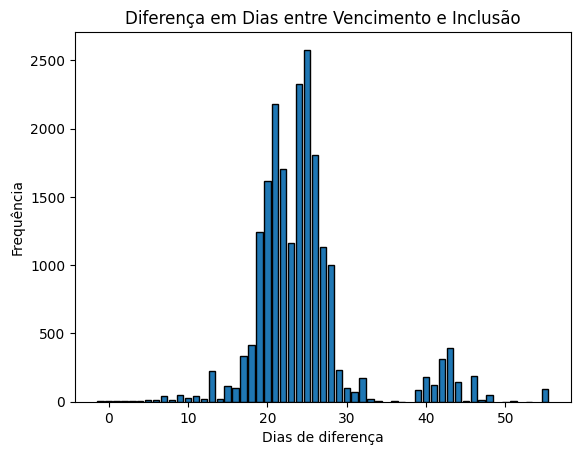

In [16]:


# Gráfico de barras
plt.bar(TipoData.index, TipoData.values, edgecolor="black")
plt.title("Diferença em Dias entre Vencimento e Inclusão")
plt.xlabel("Dias de diferença")
plt.ylabel("Frequência")
plt.show()


C:\Users\Inteli\AppData\Local\Temp\ipykernel_20692\2625632724.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  boletosPagos['vl_boleto'] = pd.to_numeric(boletosPagos['vl_boleto'], errors='coerce')


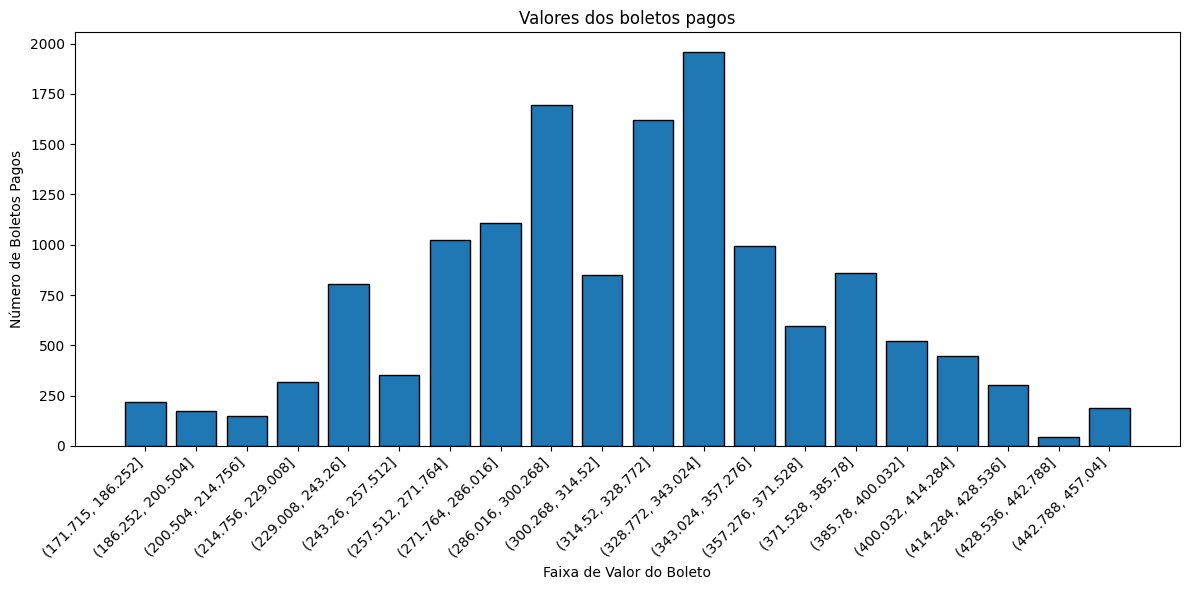

In [17]:
boletosPagos = df_atual[df_atual['status_num'] == 2]

boletosPagos['vl_boleto'] = pd.to_numeric(boletosPagos['vl_boleto'], errors='coerce')

# Remover linhas que ficaram NaN (eram inválidas)
boletosPagos = boletosPagos.dropna(subset=['vl_boleto'])

# Cria as faixas
bins = 20
boletosPagos['faixa_boleto'] = pd.cut(boletosPagos['vl_boleto'], bins=bins)

# Conta por faixa
vBoletoPagosGrouped = boletosPagos['faixa_boleto'].value_counts().sort_index()

# Gráfico
fig, ax = plt.subplots(figsize=(12,6))
ax.bar(vBoletoPagosGrouped.index.astype(str), vBoletoPagosGrouped.values, edgecolor="black")

ax.set_title("Valores dos boletos pagos")
ax.set_xlabel("Faixa de Valor do Boleto")
ax.set_ylabel("Número de Boletos Pagos")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

O código tem como objetivo analisar a distribuição dos valores dos boletos pagos. Para isso, ele filtra apenas os registros com status de pagamento concluído, converte os valores dos boletos para o formato numérico e remove eventuais dados inválidos. Em seguida, divide os valores em 20 faixas de preço e contabiliza quantos boletos estão em cada uma delas. Por fim, é gerado um gráfico de barras que exibe a quantidade de boletos pagos por faixa de valor, permitindo visualizar de forma clara a distribuição dos pagamentos e identificar as faixas de valores mais recorrentes.

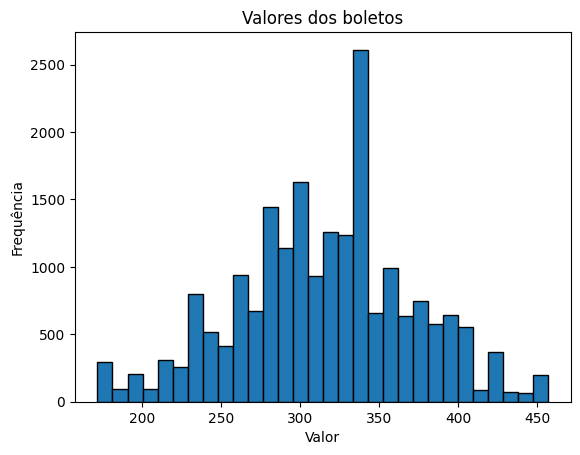

In [18]:
vBoleto = df_atual['vl_boleto'].value_counts().sort_index()

plt.hist(df_atual['vl_boleto'], bins=30, edgecolor="black")

plt.title("Valores dos boletos")
plt.xlabel("Valor")
plt.ylabel("Frequência")
plt.show()

O código realiza uma análise do valor médio dos boletos por cidade. Primeiro, ele contabiliza quantos pagadores existem em cada cidade, ordenando os resultados alfabeticamente. Em seguida, utiliza o Seaborn para criar um gráfico de barras que mostra a média do valor dos boletos (vl_boleto) para cada cidade registrada no conjunto de dados. O gráfico facilita a visualização das regiões onde os boletos apresentam valores médios mais altos ou mais baixos, permitindo identificar padrões geográficos de pagamento ou possíveis concentrações de valores elevados em determinadas localidades.

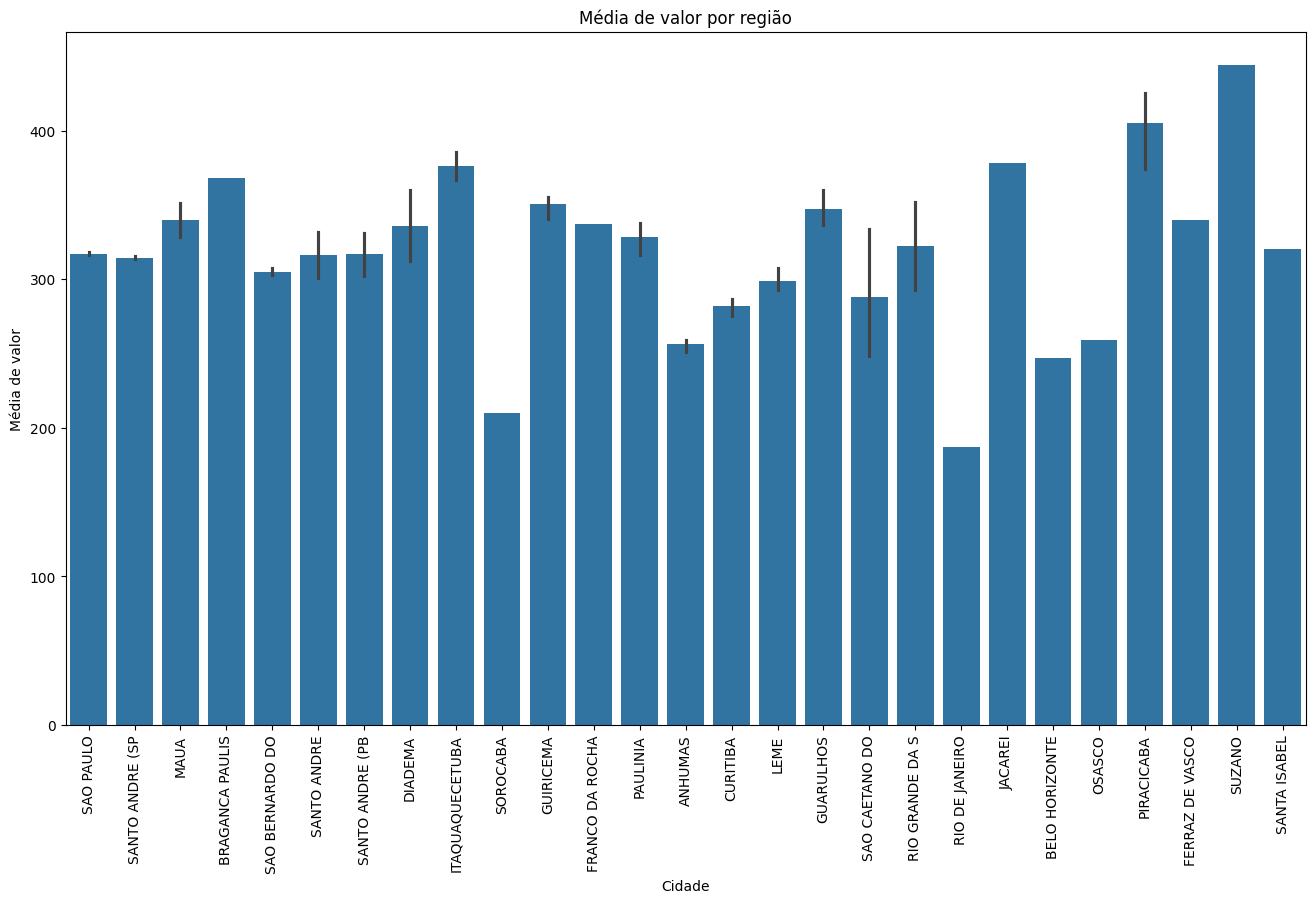

In [19]:


numeroPorCidade = df_atual['pagador_cidade'].value_counts().sort_index()

plt.figure(figsize=(16,9))
sns.barplot(x="pagador_cidade", y="vl_boleto", data=df_atual, estimator="mean")
plt.xticks(rotation=90)
plt.title("Média de valor por região")
plt.xlabel("Cidade")
plt.ylabel("Média de valor")
plt.show()

O trecho de código realiza uma análise exploratória dos dados financeiros por cidade. Primeiro, ele contabiliza o número de registros de pagadores em cada cidade usando value_counts(). Em seguida, cria um gráfico de barras com o Seaborn, onde o eixo X representa as cidades e o eixo Y mostra a média do valor dos boletos (vl_boleto) em cada uma delas. O gráfico, com as legendas rotacionadas para melhor visualização, permite identificar quais regiões possuem os boletos de maior ou menor valor médio, auxiliando na detecção de padrões geográficos de pagamento.

C:\Users\Inteli\AppData\Local\Temp\ipykernel_20692\782073141.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  boletos_incluidos = df_atual.groupby('mes_inclusao').size()
C:\Users\Inteli\AppData\Local\Temp\ipykernel_20692\782073141.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  boletos_pagos = df_atual[df_atual['status_num'] == 2].groupby('mes_pag').size()


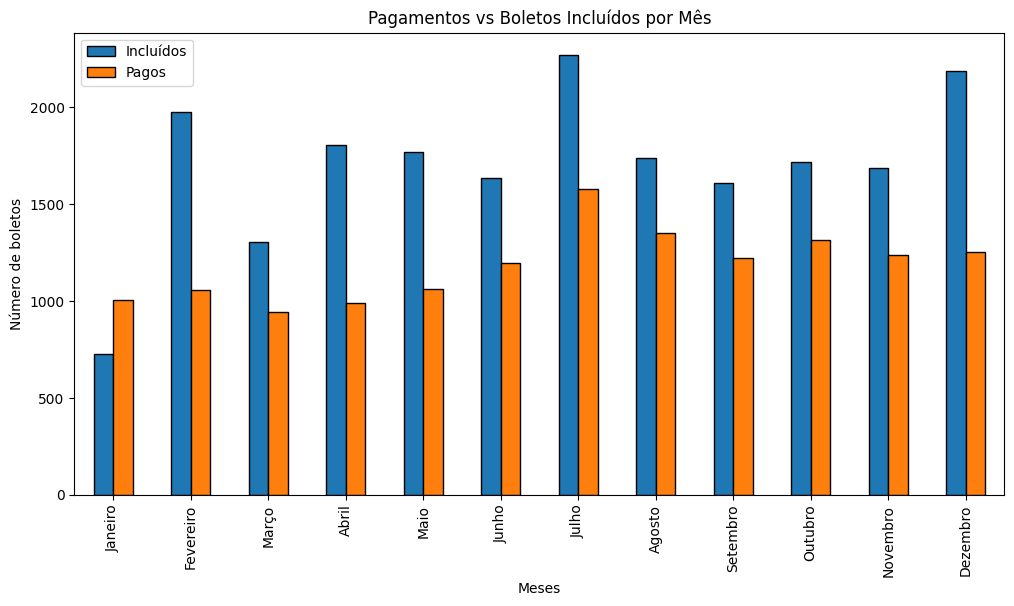

In [20]:
df_atual['mes_pag'] = pd.Categorical(df_atual['mes_pag'], categories=ordem_meses, ordered=True)
df_atual['mes_inclusao'] = pd.Categorical(df_atual['mes_inclusao'], categories=ordem_meses, ordered=True)
df_atual['mes_vencimento'] = pd.Categorical(df_atual['mes_vencimento'], categories=ordem_meses, ordered=True)
# Agrupamento
boletos_incluidos = df_atual.groupby('mes_inclusao').size()
boletos_pagos = df_atual[df_atual['status_num'] == 2].groupby('mes_pag').size()

# Unir em dataframe
df_mes = pd.concat([boletos_incluidos, boletos_pagos], axis=1)
df_mes.columns = ['Incluídos', 'Pagos']
df_mes = df_mes.fillna(0)

# Taxa de pagamento
df_mes['Taxa'] = (df_mes['Pagos'] / df_mes['Incluídos']) * 100

# Gráfico
fig, ax1 = plt.subplots(figsize=(12, 6))

df_mes[['Incluídos', 'Pagos']].plot(kind='bar', ax=ax1, edgecolor="black")
ax1.set_ylabel("Número de boletos")
ax1.set_xlabel("Meses")
ax1.set_title("Pagamentos vs Boletos Incluídos por Mês")


# Legendas
ax1.legend(loc="upper left")


plt.show()

O código realiza uma análise temporal da emissão e pagamento de boletos ao longo dos meses. Primeiro, ele organiza as colunas de mês (mes_pag, mes_inclusao e mes_vencimento) em uma ordem cronológica de janeiro a dezembro. Em seguida, agrupa os dados para contar quantos boletos foram incluídos (emitidos) e quantos foram pagos em cada mês. Esses valores são combinados em um único DataFrame, e a taxa de pagamento mensal é calculada como a proporção entre boletos pagos e incluídos. Por fim, o código gera um gráfico de barras comparativo, permitindo visualizar o volume de emissões e pagamentos ao longo do ano e identificar sazonalidades ou períodos com maior ou menor adesão ao pagamento.

## 3.3 Hipóteses

 Nesta análise, foram levantadas hipóteses relacionadas ao comportamento de pagamento de boletos pelos usuários da plataforma. O objetivo é identificar padrões e fatores que influenciam o tempo de pagamento. Essas hipóteses servem como base para exploração de dados e para a criação do modelo preditivo, auxiliando na compreensão dos fatores que impactam atrasos, pontualidade nos pagamentos e permitem identificar quais variáveis impactão ou não no pagamento de boletos.

### 3.3.1 Hipótese 1 - Dias necessários para o pagamento de boletos

**Tese:** A maioria dos boletos, tanto pagos quanto não pagos, possui um intervalo entre a data de inclusão e a data de vencimento concentrado entre 20 e 30 dias.

**Resultado:** Positivo, ambos possuem um intervalo concentrado entre 20 e 30 dias.

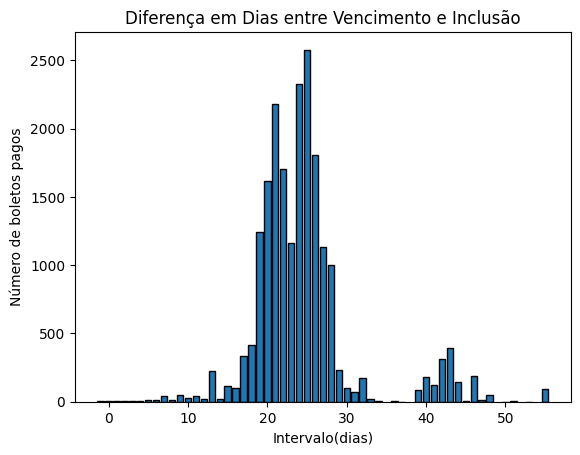

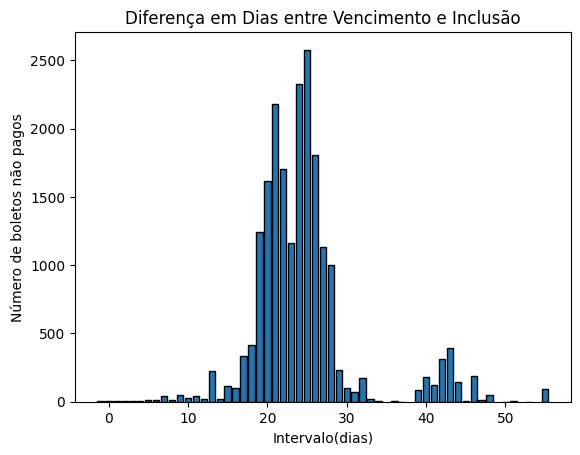

In [21]:


# Gráfico de barras - Boletos Pagos
plt.bar(TipoData.index, TipoData.values, edgecolor="black")
plt.title("Diferença em Dias entre Vencimento e Inclusão")
plt.xlabel("Intervalo(dias)")
plt.ylabel("Número de boletos pagos")
plt.show()

# Gráfico de barras - Boletos Não Pagos
plt.bar(TipoData.index, TipoData.values, edgecolor="black")
plt.title("Diferença em Dias entre Vencimento e Inclusão")
plt.xlabel("Intervalo(dias)")
plt.ylabel("Número de boletos não pagos")
plt.show()

### 3.3.2 Hipótese 2 -  O período do ano influencia diretamente na taxa de pagamento de boletos.

&nbsp;&nbsp;&nbsp;&nbsp; Esta hipótese busca confirmar que a taxa de pagamento de boletos varia de acordo com o mês ou período do ano, influenciada por fatores sazonais e econômicos. Em determinados meses, como dezembro (festividades de fim de ano) ou março/abril (pagamento de impostos), pode haver uma maior pressão financeira, reduzindo a taxa de quitação de boletos. Já em períodos de maior liquidez, como meses de recebimento de 13º salário ou distribuição de bônus corporativos, a taxa de pagamento tende a aumentar. Além disso, mudanças na governança ou estratégias financeiras das empresas ao longo do ano podem impactar diretamente a capacidade de honrar pagamentos.

&nbsp;&nbsp;&nbsp;&nbsp; No gráfico abaixo, análisamos mais de 30 mil boletos entre um período de 12 meses, utilizando Python e bibliotecas como Pandas, Matplotlib e Seaborn. O eixo X representa os meses do ano, enquanto o Y representa o número de boletos. A barra em azul representa os boletos incluídos, a laranja os boletos pagos e a linha vermelha representa a taxa de pagamento em porcentagem.


C:\Users\Inteli\AppData\Local\Temp\ipykernel_20692\3620631559.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  boletos_incluidos = df_atual.groupby('mes_inclusao').size()
C:\Users\Inteli\AppData\Local\Temp\ipykernel_20692\3620631559.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  boletos_pagos = df_atual[df_atual['status_num'] == 2].groupby('mes_pag').size()


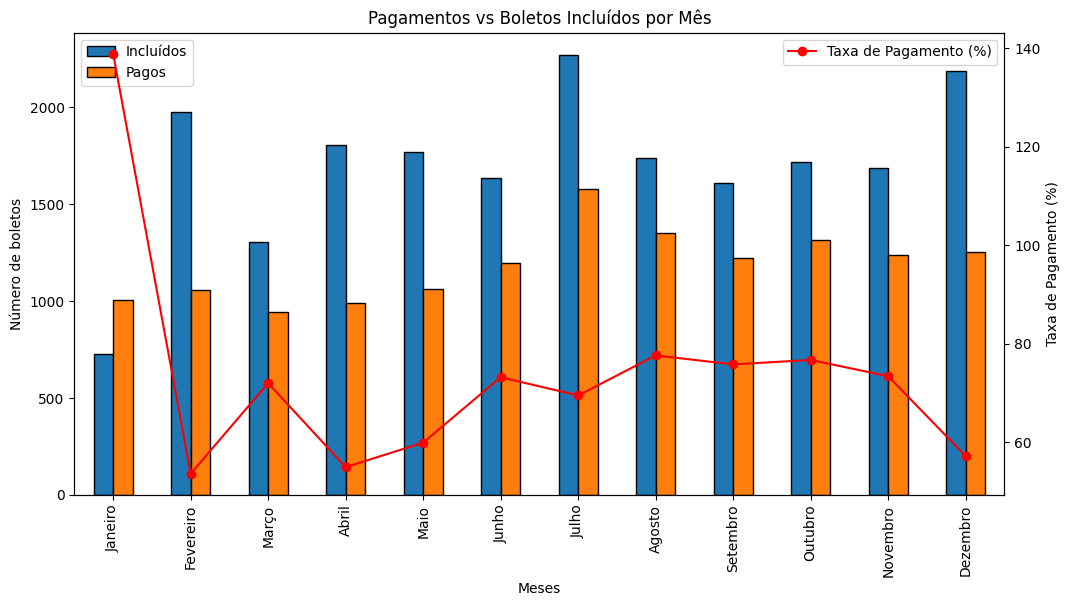

In [22]:


df_atual['mes_pag'] = pd.Categorical(df_atual['mes_pag'], categories=ordem_meses, ordered=True)
df_atual['mes_inclusao'] = pd.Categorical(df_atual['mes_inclusao'], categories=ordem_meses, ordered=True)
df_atual['mes_vencimento'] = pd.Categorical(df_atual['mes_vencimento'], categories=ordem_meses, ordered=True)

# Agrupamento
boletos_incluidos = df_atual.groupby('mes_inclusao').size()
boletos_pagos = df_atual[df_atual['status_num'] == 2].groupby('mes_pag').size()

# Unir em dataframe
df_mes = pd.concat([boletos_incluidos, boletos_pagos], axis=1)
df_mes.columns = ['Incluídos', 'Pagos']
df_mes = df_mes.fillna(0)

# Taxa de pagamento
df_mes['Taxa'] = (df_mes['Pagos'] / df_mes['Incluídos']) * 100

# Gráfico
fig, ax1 = plt.subplots(figsize=(12, 6))

df_mes[['Incluídos', 'Pagos']].plot(kind='bar', ax=ax1, edgecolor="black")
ax1.set_ylabel("Número de boletos")
ax1.set_xlabel("Meses")
ax1.set_title("Pagamentos vs Boletos Incluídos por Mês")

# Eixo secundário
ax2 = ax1.twinx()
ax2.plot(df_mes.index, df_mes['Taxa'], color="red", marker="o", label="Taxa de Pagamento (%)")
ax2.set_ylabel("Taxa de Pagamento (%)")

# Legendas
ax1.legend(loc="upper left")
ax2.legend(loc="upper right")

plt.show()

    

&nbsp;&nbsp;&nbsp;&nbsp; A análise do gráfico revela padrões importantes no comportamento de pagamento dos boletos. Em janeiro, observa-se que a quantidade de pagamentos supera a de inclusões, o que desmonstra o impacto das festividades e despesas concentradas no fim do ano. Isso ocorre porque em dezembro há um aumento expressivo na emissão de boletos, enquanto em janeiro, período de retomada das atividades, o número de novos boletos é significativamente menor.

&nbsp;&nbsp;&nbsp;&nbsp; Além disso, nota-se que em abril a taxa de pagamentos apresenta um dos menores índices do ano, o que pode estar associado à sobrecarga financeira causada pelo pagamento de impostos obrigatórios, como o Imposto de Renda e tributos anuais. Esse padrão reforça a influência de fatores econômicos e sazonais na dinâmica de pagamento.

**Resultado:** Portanto, é possível afirmar que o período do ano influncia diretamente no pagamento de boletos.

### 3.3.3 Hipótese 3 - O tempo necessário para pagamento de boletos varia de acordo com o perfil financeiro e comportamento dos clientes

&nbsp;&nbsp;&nbsp;&nbsp; Esta hipótese busca confirmar que o tempo necessário para pagamento de boletos varia de acordo com o perfil financeiro e comportamento dos clientes. Observa-se que grande parte dos boletos é quitada dentro dos primeiros 30 dias após a inclusão, indicando que muitos clientes priorizam pagamentos imediatos. Por outro lado, uma parcela menor apresenta atrasos mais longos, podendo estar relacionada a dificuldades financeiras temporárias, menor disciplina de pagamento ou atrasos na compensação bancária.

&nbsp;&nbsp;&nbsp;&nbsp; No gráfico abaixo, o eixo X representa os dias necessários para pagar, enquanto o eixo Y representa o número de boletos quitados em cada período. Cada ponto azul indica a quantidade de boletos pagos após determinado número de dias desde a inclusão.

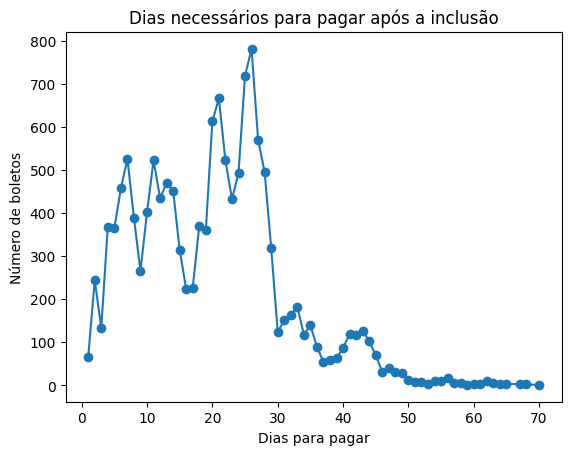

In [23]:

    # Gráfico de barras
plt.plot(DiasParaPagar.index, DiasParaPagar.values, marker="o")
plt.title("Dias necessários para pagar após a inclusão")
plt.xlabel("Dias para pagar")
plt.ylabel("Número de boletos")
plt.show()


&nbsp;&nbsp;&nbsp;&nbsp; A análise do gráfico revela padrões importantes no comportamento de pagamento. Observa-se um pico significativo entre 20 e 30 dias, sugerindo que a maioria dos clientes paga dentro do prazo mensal típico. Além disso, o número de boletos pagos decresce rapidamente após 40 dias, evidenciando que atrasos prolongados são menos frequentes, mas ainda presentes, indicando a necessidade de monitoramento e estratégias de cobrança para evitar inadimplência.

&nbsp;&nbsp;&nbsp;&nbsp; **Resultado:** Portanto, é possível afirmar que o tempo de pagamento de boletos segue um padrão concentrado nos primeiros 30 dias, com uma diminuição acentuada à medida que os dias avançam.

### 3.3.4 Hipótese 4 - Boletos com valores mais altos tendem a ser pagos em um maior número de dias após a emissão, enquanto boletos de menor valor costumam ser liquidados mais rapidamente.

&nbsp;&nbsp;&nbsp;&nbsp; Essa hipótese busca afirmar se valores elevados representam um maior impacto no orçamento do cliente, já que exigem maior planejamento financeiro, o que pode gerar atrasos ou maior tempo médio até o pagamento.

&nbsp;&nbsp;&nbsp;&nbsp; Esse comportamento pode estar associado tanto ao poder aquisitivo dos clientes quanto à priorização de despesas no ciclo financeiro. 

&nbsp;&nbsp;&nbsp;&nbsp; No gráfico abaixo, o eixo X representa os dias necessários para pagar o boleto e o Y o valor do boleto.

C:\Users\Inteli\AppData\Local\Temp\ipykernel_20692\3110556428.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  DiasParaPagar['vl_boleto'] = pd.to_numeric(df_atual['vl_boleto'], errors='coerce')


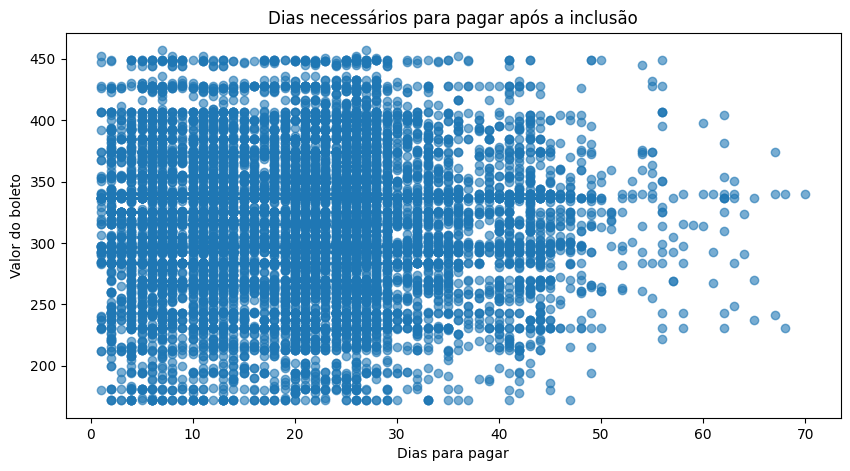

In [24]:
DiasParaPagar = df_atual[df_atual['dias_para_pagar'] > 0] 
DiasParaPagar['vl_boleto'] = pd.to_numeric(df_atual['vl_boleto'], errors='coerce')
plt.figure(figsize=(10,5)) 
plt.scatter(DiasParaPagar['dias_para_pagar'], DiasParaPagar['vl_boleto'], alpha=0.6, marker="o") 
plt.title("Dias necessários para pagar após a inclusão") 
plt.xlabel("Dias para pagar") 
plt.ylabel("Valor do boleto") 
plt.show()

&nbsp;&nbsp;&nbsp;&nbsp; A partir da análise do gráfico acima, é possível identificar que não há uma tendência linear clara entre essas variáveis. A maioria dos pagamentos ocorre em até 30 dias, concentrando-se em boletos de R$ 200 a R$ 400. Casos isolados de valores acima de R$ 450 mostram pagamentos tanto rápidos quanto atrasados, sugerindo que o valor sozinho não determina o tempo de quitação. Após 40 dias, os pagamentos se tornam mais raros. Assim, o prazo para pagamento parece depender mais de fatores como comportamento do cliente, sazonalidade ou disciplina financeira, indicando que o valor do boleto deve ser analisado junto a outras variáveis em modelos preditivos.

**Resultado:** Portanto, é possível afirmar que NÃO há uma relação clara entre o valor do boleto e tempo necessário para pagar.


### 3.3.5 Hipótese 5 - A média de acesso de pessoas que pagaram o boleto é maior que as que não pagaram.

&nbsp;&nbsp;&nbsp;&nbsp; Essa hipótese busca confirmar que usuários que efetivam o pagamento de seus boletos tendem a apresentar uma quantidade de acessos à plataforma significativamente maior do que aqueles que não realizam o pagamento.

&nbsp;&nbsp;&nbsp;&nbsp; O número de acessos pode refletir o nível de engajamento do usuário com a plataforma. Um usuário mais engajado costuma ter maior contato com os serviços, maior percepção de valor e, consequentemente, maior probabilidade de honrar o pagamento. Por outro lado, usuários com baixa frequência de acessos podem demonstrar desinteresse ou menor vínculo, aumentando a chance de inadimplência.

&nbsp;&nbsp;&nbsp;&nbsp; Se a hipótese for confirmada, a quantidade de acesso pode se tornar uma forte variável na implementação do modelo preditivo, pois se torna um dos indicadores de pagamento e influencia na busca de inadimplentes.

&nbsp;&nbsp;&nbsp;&nbsp; No gráfico abaixo, o eixo X possui dois valores, os boletos pagos e não pagos, enquanto o eixo Y representa a média de acessos dos usuários de cada um desses grupos.

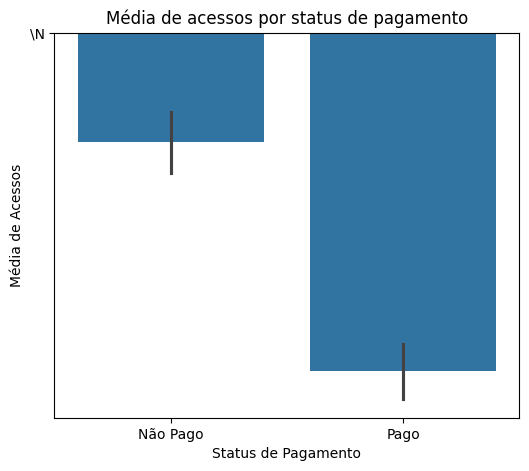

In [25]:
plt.figure(figsize=(6,5))
sns.barplot(x="pago/n", y="qtd_acessos_pagador", data=df_atual, estimator="mean")

plt.title("Média de acessos por status de pagamento")
plt.xlabel("Status de Pagamento")
plt.ylabel("Média de Acessos")
plt.show()


**Resultado:** Portanto, através da análise do gráfico, é possível confirmar que a média de acessos das pessoas que pagaram os boletos é consideravelmente maior que das pessoas que não pagaram.

### 3.3.6. Hipótese 6 - Média de valor entre boletos pagos e não pagos

&nbsp;&nbsp;&nbsp;&nbsp; Esta hipótese busca afirmar que a média de valor é maior para os boletos com status 'Não Pago', sugerindo que valores mais altos podem influenciar negativamente a quitação dos boletos.

C:\Users\Inteli\AppData\Local\Temp\ipykernel_20692\3468957271.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  DiasParaPagar['vl_boleto'] = pd.to_numeric(df_atual['vl_boleto'], errors='coerce')


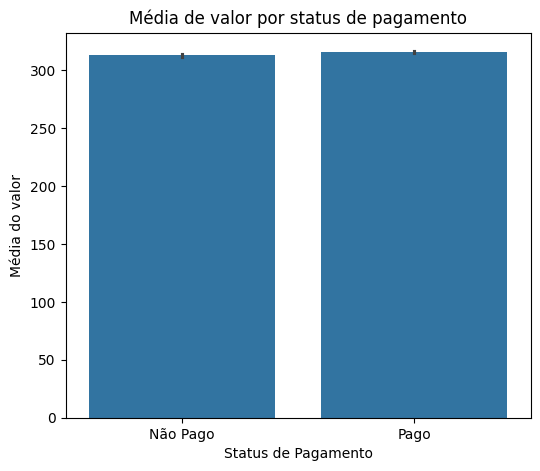

In [26]:

mapping = {0: 'Não Pago', 1: 'Não Pago', 2: 'Pago'}
df_atual['pago/n'] = df_atual['status_num'].map(mapping)

df_atual['vl_boleto'] = pd.to_numeric(df_atual['vl_boleto'], errors='coerce')
DiasParaPagar['vl_boleto'] = pd.to_numeric(df_atual['vl_boleto'], errors='coerce')
plt.figure(figsize=(6,5))
sns.barplot(x="pago/n", y="vl_boleto", data=df_atual, estimator="mean")

plt.title("Média de valor por status de pagamento")
plt.xlabel("Status de Pagamento")
plt.ylabel("Média do valor")
plt.show()

**Resultado**: Após a análise do gráfico, pode-se concluir que a média de valor entre boletos pagos e não pagos é praticamente igual, o que anula completamente a hipótese de que a média de valor de boletos não pagos é maior.


&nbsp;&nbsp;&nbsp;&nbsp; As hipóteses levantadas permitem direcionar análises quantitativas para verificar a influência de diferentes fatores sobre o comportamento de pagamento. A avaliação de padrões relacionados a valores, frequência de acessos e histórico de pagamentos ajuda a confirmar ou rejeitar essas hipóteses, identificando as variáveis relevantes para a criação do nosso modelo preditivo destinado a Finnet.


## 4. Criação do Modelo Preditivo

&nbsp;&nbsp;&nbsp;&nbsp; Nessa seção, foram desenvolvidos os modelos preditivos necessários para atender às entregas propostas no TAPI, cada um deles com objetivos específicos:


- Modelo de tendência de pagamento: estruturado como um problema de classificação e de aprendizado supervisionado, esse modelo prevê se o pagamento ocorrerá em dia, com atraso ou se resultará em inadimplência, fornecendo uma visão antecipada do comportamento do pagador.

- Modelo da melhor janela de pagamento provável: desenvolvido para identificar o período mais adequado em que o pagador tende a realizar o pagamento, oferecendo subsídios para ações proativas de cobrança e definição de prazos estratégicos. Esse modelo será estruturado como um problema de regressão e a aprendizagem será feita de forma supervisionada.

- Modelo de impacto projetado no fluxo de recebimentos: criado para estimar como diferentes cenários de pagamento (adimplência, atraso ou inadimplência) afetam o fluxo de caixa futuro, permitindo ao grupo avaliar riscos financeiros e tomar decisões de planejamento. Esse modelo será estruturado como um problema de regressão e a aprendizagem será feita de forma supervisionada.

### 4.1 Tratamento dos dados

&nbsp;&nbsp;&nbsp;&nbsp; Durante o processo de criação de gráficos e hipóteses, alguns dos novos dados criados durante esse processo não foram previamente tratados e normalizados, dessa forma, realizamos novamente a substituição dos valores nulos, codificação das variáveis categóricas e substituição dos valores ausentes.

### 4.1.1 Substituindo valores nulos

&nbsp;&nbsp;&nbsp;&nbsp; O código abaixo, substitui os valores ausentes preenchidos por NaN (Not a Number) das tabelas **dias_para_pagar**, **qtd_acessos_pagador_norm** e **pago/n** por 0, assim possibilitando a utilização dessas dados pelo modelo preditivo.

In [27]:
df_atual = TabelaGeral

df_atual['banco'] = df_atual['banco'].astype(str)
df_atual['tipo_juros'] = df_atual['tipo_juros'].astype(str)
df_atual['tipo_multa'] = df_atual['tipo_multa'].astype(str)

Banco_encoder = LabelEncoder()
Cidade_Pagador_encoder = LabelEncoder()
Status_boleto_encoder = LabelEncoder()
Juros_encoder = LabelEncoder()
cep_encoder = LabelEncoder()
Multa_encoder = LabelEncoder()
Tipo_pagador_encoder = LabelEncoder()

Banco_encoder.fit(df_atual['banco'])
df_atual['banco'] = Banco_encoder.fit_transform(df_atual['banco'])

Tipo_pagador_encoder.fit(df_proc['pagador_cnpjcpf'])
df_proc['pagador_cnpjcpf'] = Tipo_pagador_encoder.fit_transform(df_proc['pagador_cnpjcpf'])

Cidade_Pagador_encoder.fit(df_atual['pagador_cidade'])
df_atual['pagador_cidade'] = Cidade_Pagador_encoder.transform(df_atual['pagador_cidade'])

Status_boleto_encoder.fit(df_atual['status_boleto'])
df_atual['status_boleto'] = Status_boleto_encoder.transform(df_atual['status_boleto'])

Juros_encoder.fit(df_atual['tipo_juros'])
df_atual['tipo_juros'] = Juros_encoder.transform(df_atual['tipo_juros'])

Multa_encoder.fit(df_atual['tipo_multa'])
df_atual['tipo_multa'] = Multa_encoder.transform(df_atual['tipo_multa'])

df_atual['pagador_cep'] = df_atual['pagador_cep'].fillna('0').astype(str)
cep_encoder.fit(df_atual['pagador_cep'])
df_atual['pagador_cep'] = cep_encoder.transform(df_atual['pagador_cep'])


df_atual['pagador_cidade'] = Cidade_Pagador_encoder.inverse_transform(df_atual['pagador_cidade'])
df_atual['status_boleto'] = Status_boleto_encoder.inverse_transform(df_atual['status_boleto'])

# Convertendo Datas em string para DATETIME

df_atual['data_vencto'] = pd.to_datetime(df_atual['data_vencto'], errors='coerce', dayfirst=True)
df_atual['data_inclusao'] = pd.to_datetime(df_atual['data_inclusao'], errors='coerce', dayfirst=True)
df_atual['dt_pagto'] = pd.to_datetime(df_atual['dt_pagto'], errors='coerce', dayfirst=True)

# Convertendo de INT para numérico

df_atual['vl_boleto'] = pd.to_numeric(df_atual['vl_boleto'], errors='coerce')
df_atual['juros'] = pd.to_numeric(df_atual['juros'], errors='coerce')

# Criando coluna em númérico do status do boleto
print(df_atual['status_boleto'])
mapping = {'REGISTRADO': 0, 'BAIXADO': 1, 'LIQUIDADO': 2}
df_atual['status_num'] = df_atual['status_boleto'].map(mapping)



# Dicionário de mapeamento mês
mapping = {
    1: 'Janeiro', 2: 'Fevereiro', 3: 'Março', 4: 'Abril',
    5: 'Maio', 6: 'Junho', 7: 'Julho', 8: 'Agosto',
    9: 'Setembro', 10: 'Outubro', 11: 'Novembro', 12: 'Dezembro'
}


# Criar colunas de mês
df_atual['mes_pag'] = df_atual['dt_pagto'].dt.month.map(mapping)
df_atual['mes_inclusao'] = df_atual['data_inclusao'].dt.month.map(mapping)
df_atual['mes_vencimento'] = df_atual['data_vencto'].dt.month.map(mapping)
ordem_meses = list(mapping.values())

df_atual['dia_vencimento'] = df_atual['data_vencto'].dt.day
print(df_atual['dia_vencimento'])
ordem_meses = list(mapping.values())
# Filtrando boletos pagos
boletosPagos = df_atual[(df_atual['status_num'] == 2)]

DiasParaPagar = (boletosPagos['dt_pagto'] - boletosPagos['data_inclusao']).dt.days
df_atual['dias_para_pagar'] = DiasParaPagar
DiasParaVencer = (df_atual['data_vencto'] - df_atual['data_inclusao']).dt.days
df_atual['dias_para_vencer'] = DiasParaVencer
DiasParaPagar = DiasParaPagar.value_counts().sort_index()


dataVen = df_atual['data_vencto']
dataInc = df_atual['data_inclusao']
Datas = (dataVen - dataInc).dt.days

TipoData = Datas.value_counts()
TipoData = TipoData.sort_index()

mapping = {0: 'Não Pago', 1: 'Não Pago', 2: 'Pago'}
df_atual['pago/n'] = df_atual['status_num'].map(mapping)
df_atual['dias_para_pagar'] = df_atual['dias_para_pagar'].replace(np.nan, 0)
df_atual['qtd_acessos_pagador_norm'] = df_atual['qtd_acessos_pagador_norm'].replace(np.nan, 0)
df_atual['qtd_acessos_pagador'] = df_atual['qtd_acessos_pagador'].replace(np.nan, 0)
df_atual['pago/n'] = df_atual['pago/n'].fillna(0)
df_atual['pago/n'] = df_atual['pago/n'].replace('\\N', 0)

0         REGISTRADO
1         REGISTRADO
2         REGISTRADO
3         REGISTRADO
4         REGISTRADO
             ...    
380283    REGISTRADO
380284    REGISTRADO
380285    REGISTRADO
380286    REGISTRADO
380287    REGISTRADO
Name: status_boleto, Length: 380288, dtype: object
0         30.0
1         23.0
2         24.0
3         29.0
4         28.0
          ... 
380283    14.0
380284    21.0
380285    21.0
380286    28.0
380287    28.0
Name: dia_vencimento, Length: 380288, dtype: float64


&nbsp;&nbsp;&nbsp;&nbsp; O código realiza um extenso pré-processamento dos dados de boletos, com o objetivo de padronizar, limpar e preparar a base para análises e modelagem preditiva. Inicialmente, são feitas conversões de tipo para garantir consistência nas variáveis categóricas e numéricas. Em seguida, aplica-se a técnica de codificação com LabelEncoder para transformar informações textuais, como banco, cidade, tipo de juros e status do boleto, em valores numéricos interpretáveis pelos algoritmos de aprendizado de máquina. 

&nbsp;&nbsp;&nbsp;&nbsp; As colunas de datas são convertidas para o formato datetime, permitindo o cálculo de intervalos de tempo, como dias entre inclusão e pagamento ou entre inclusão e vencimento. Além disso, são criadas novas variáveis derivadas que facilitam a análise temporal e a segmentação dos boletos. Por fim, realiza-se o tratamento de valores ausentes e inconsistentes, garantindo integridade e coerência nos dados. Dessa forma, o conjunto final torna-se padronizado, completo e adequado para análises estatísticas e predições de comportamento de pagamento.

### 4.1.2 Transformando novas features em Label Encoder

&nbsp;&nbsp;&nbsp;&nbsp; Após a criação de novas features durante o processo de criação dos gráficos, foi necessário transformar as novas features desenvolvidas nos gráficos, hipóteses e na preparação do modelo preditivo, para o formato Label Encoder, tramsformando assim variáveis categóricas como (**mes_inclusão**, **mes_pag**, **pagador_inscricao_hash**, **pago/n (pago ou não)** e **mes_vencto**) em números que representam cada uma das categorias, para que assim, os dados possam ser entendidos pelo modelo.

In [28]:

mesEncoder = LabelEncoder()
mesEncoder.fit(df_atual['mes_inclusao'])
df_atual['mes_inclusao'] = mesEncoder.fit_transform(df_atual['mes_inclusao'])

mesEncoder.fit(df_atual['mes_pag'])
df_atual['mes_pag'] = mesEncoder.fit_transform(df_atual['mes_pag'])

pagadorHash = LabelEncoder()
pagadorHash.fit(df_atual['pagador_inscricao_hash'])
df_atual['pagador_inscricao_hash'] = pagadorHash.fit_transform(df_atual['pagador_inscricao_hash'])

df_atual['pago/n'] = df_atual['pago/n'].astype(str)
pagoEncoder = LabelEncoder()
pagoEncoder.fit(df_atual['pago/n'])
df_atual['pago/n'] = pagoEncoder.transform(df_atual['pago/n'])

mesVencto = LabelEncoder()
mesVencto.fit(df_atual['mes_vencimento'])
df_atual['mes_vencimento'] = mesVencto.fit_transform(df_atual['mes_vencimento'])



&nbsp;&nbsp;&nbsp;&nbsp; Esse trecho do código dá continuidade ao processo de preparação dos dados, realizando a codificação de variáveis categóricas relacionadas ao tempo e ao identificador do pagador. Primeiramente, as colunas referentes aos meses de inclusão, pagamento e vencimento são convertidas para valores numéricos por meio do LabelEncoder, permitindo que os algoritmos interpretem essas informações de forma quantitativa. 

&nbsp;&nbsp;&nbsp;&nbsp; Em seguida, a coluna pagador_inscricao_hash, que identifica de forma única cada pagador, também é transformada em números, mantendo o anonimato e viabilizando sua utilização em modelos de machine learning. Por fim, a variável pago/n, que indica se o boleto foi pago ou não, é convertida para o tipo string e posteriormente codificada, garantindo consistência nos dados categóricos. Assim, o código padroniza e numera todas as variáveis relevantes, preparando o conjunto de dados para análises preditivas e estatísticas.

### 4.1.3 Normalizando os dados

&nbsp;&nbsp;&nbsp;&nbsp; Durante a criação do modelo preditivo, notamos que a alta dispersão de valores dos dados interfere diretamente na acurácia e resultados do modelo. Portanto, se fez necessário criar uma escala padrão para as colunas, assim transformando as linhas de algumas colunas em números em uma escala de (0,1) para melhor aproximação dos dados e assim garantindo melhores resultados e acurácia nos modelos criados. 

In [29]:
# Colunas categóricas que ainda são strings
categoricas = ['pagador_cnpjcpf', 'pago/n', 'banco', 'tipo_juros', 'tipo_multa']

for col in categoricas:
    # Preencher nulos e converter para string
    df_atual[col] = df_atual[col].fillna('NA').astype(str)
    # Label encoding
    le = LabelEncoder()
    df_atual[col] = le.fit_transform(df_atual[col])

# Agora MinMaxScaler só nas colunas numéricas
numericas = ['pagador_inscricao_hash', 'mes_pag', 'mes_inclusao', 'dias_para_pagar',
             'dias_para_vencer', 'pago/n', 'banco', 'dia_vencimento', 'mes_vencimento', 'pagador_cnpjcpf']

scaler = MinMaxScaler(feature_range=(0, 1))
for col in numericas:
    df_atual[col + '_norm'] = scaler.fit_transform(df_atual[[col]])


&nbsp;&nbsp;&nbsp;&nbsp; O código realiza o pré-processamento dos dados, começando pela transformação de variáveis categóricas (como “pagador_cnpjcpf”, “pago/n”, “banco”, “tipo_juros” e “tipo_multa”) em valores numéricos usando LabelEncoder, o que permite que modelos de Machine Learning consigam interpretá-las. Em seguida, ele aplica o MinMaxScaler nas variáveis numéricas (como “mes_pag”, “dias_para_pagar”, “mes_vencimento”, entre outras), normalizando seus valores entre 0 e 1. Isso padroniza a escala dos dados, evitando que atributos com valores muito altos influenciem desproporcionalmente os resultados dos algoritmos de aprendizado.

## 4.2 Modelo Preditivo de Tendência de Pagamentos

&nbsp;&nbsp;&nbsp;&nbsp; O modelo preditivo de tendência de pagamentos tem como objetivo identificar a probabilidade de o devedor realizar o próximo pagamento em dia, com atraso ou em inadimplência. Trata-se de um problema de aprendizado supervisionado, classificado como classificação multiclasse. Para viabilizar o treinamento, foi criada a variável alvo denominada “Status de Pagamento”, utilizada como variável Y no processo de modelagem preditiva.

### 4.2.1 Features

&nbsp;&nbsp;&nbsp;&nbsp; As features correspondem às variáveis explicativas utilizadas pelo modelo preditivo, ou seja, são os atributos extraídos das colunas dos boletos que fornecem informações relevantes para estimar a tendência de pagamento do usuário. Cada feature representa um aspecto do comportamento do pagador ou das características dos boletos.

#### 4.2.1.1 Variável Alvo Y (Status do Pagamento)

&nbsp;&nbsp;&nbsp;&nbsp; No desenvolvimento do modelo de tendência de pagamento, fez se necessário estabelecer, para cada boleto, qual foi o resultado do pagamento: em dia, em atraso ou inadimplente. Essa informação é representada pela variável alvo (y), que corresponde ao valor que o modelo deve aprender a prever.

&nbsp;&nbsp;&nbsp;&nbsp; Em outras palavras, enquanto as features (variáveis independentes) fornecem as características descritivas dos boletos e dos pagadores, a variável alvo indica o comportamento final que se deseja estimar. No caso em questão, a variável alvo foi definida como “Status de Pagamento”, classificando cada boleto em uma das três categorias mencionadas. Essa categorização serve de referência durante o treinamento, permitindo que o algoritmo aprenda padrões e consiga, posteriormente, prever a tendência de pagamento de novos boletos.

&nbsp;&nbsp;&nbsp;&nbsp; No código abaixo foi utilizada a data de vencimento e de pagamento para calcular o número de dias que cada boleto levou para ser pago. Se o número de dias for qualquer número positivo maior que 0, significa que o boleto foi pago em dia, se for entre -1 e -30, significa que o boleto foi pago com atraso e se tiver um valor menor que -30 (Ou seja, demorou mais de 30 dias para pagar) o boleto é considerado como inadimplente.

In [30]:
diasNecessáriosParaPagar = (df_atual['data_vencto'] - df_atual['dt_pagto']).dt.days

df_atual['status_do_pagamento'] = None
# Definir status do pagamento
df_atual.loc[diasNecessáriosParaPagar >= 0, 'status_do_pagamento'] = 'em dia'
df_atual.loc[(diasNecessáriosParaPagar <= -1) & (diasNecessáriosParaPagar >= -30), 'status_do_pagamento'] = 'atrasado'
df_atual.loc[diasNecessáriosParaPagar <= -31, 'status_do_pagamento'] = 'inadimplente'
print(df_atual['status_do_pagamento'].value_counts())

df_atual.loc[diasNecessáriosParaPagar >= 0, 'score_boleto'] = 1
df_atual.loc[(diasNecessáriosParaPagar <= -1) & (diasNecessáriosParaPagar >= -30), 'score_boleto'] =  ((diasNecessáriosParaPagar) / 31) + 1 
df_atual.loc[diasNecessáriosParaPagar <= -31, 'score_boleto'] = 0

# Remover coluna antiga se existir
if 'score_boleto_media' in df_atual.columns:
    df_atual = df_atual.drop(columns=['score_boleto_media'])

# Preencher valores ausentes
df_atual['status_do_pagamento'] = df_atual['status_do_pagamento'].fillna('inadimplente')

# Calcular média por pagador_inscricao_hash
feature_pagador = df_atual.groupby("pagador_inscricao_hash")["score_boleto"].mean()

# Criar coluna de score médio usando map (sem merge)
df_atual['score_boleto_media'] = df_atual['pagador_inscricao_hash'].map(feature_pagador)
# Verificar resultado
print(df_atual['score_boleto_media'].value_counts())


df_atual['score_boleto_media'] = df_atual['score_boleto_media'].fillna(1)

print(df_atual.head(20))



status_do_pagamento
em dia          110886
atrasado        106722
inadimplente       960
Name: count, dtype: int64
score_boleto_media
1.000000    26194
0.967742    11500
0.983871     5406
0.978495     4871
0.935484     4004
            ...  
0.338710        3
0.806452        3
0.150538        3
0.161290        1
0.129032        1
Name: count, Length: 2228, dtype: int64
    id_grupo  id_beneficiario  Numero_do_boleto data_inclusao status_boleto  \
0         41            129.0         475124351    2025-06-24    REGISTRADO   
1         41             79.0         475937945    2025-06-27    REGISTRADO   
2         41             85.0         476378993    2025-06-30    REGISTRADO   
3         41             85.0         476379036    2025-06-30    REGISTRADO   
4         41             85.0         476379099    2025-06-30    REGISTRADO   
5         41             85.0         476379105    2025-06-30    REGISTRADO   
6         41             85.0         476379118    2025-06-30    REGISTRADO

#### 4.2.1.2 Variável X

&nbsp;&nbsp;&nbsp;&nbsp; O X representa o conjunto de variáveis independentes, também chamadas de features, que reúnem todas as informações utilizadas pelo modelo para aprender e prever a tendência de pagamento. No caso dos boletos, essas variáveis correspondem às colunas que descrevem características do boleto e do comportamento do pagador. Em resumo, o X é a entrada do modelo, formada por todos os atributos relevantes que permitem identificar padrões e antecipar se o pagamento ocorrerá em dia, com atraso ou inadimplente.

&nbsp;&nbsp;&nbsp;&nbsp; As features utilizadas no modelo de tendência de pagamentos foram:

- **Valor de boleto normalizado:** O valor do boleto é uma variável essencial para a predição do modelo preditivo, já que comprovamos através dos gráficos, que o valor do boleto tem impacto direto no pagamento do mesmo.
- **Quantidade de acessos:** A quantidade de acessos por pagador no boleto em específico é decisivo na predição de pagamento de boletos, já que através das hipóteses, foi comprovado que a média de acessos para os pagadores é muito maior do que aqueles que não pagam. Além disso, se a quantidade de acessos for igual a 0, há uma alta chance do boleto não ser pago, a menos que esteja em débito automático.
- **Número de inscrição do pagador em hash:** A inscrição do jogador em hash ajuda a separar dados de acordo com um pagador.
- **Juros:** O valor de juros de um boleto ajuda a identificar se o boleto será pago ou não, já que com um alto valor de juros, há uma alta chance do boleto não ser pago, enquanto um valor de juros igual a 0 representa que o boleto ainda não foi atrasado.
- **Mes_Vencimento:** Através da hipótese 2, foi comprovado que o mês de vencimento impacta diretamente no pagamento de boletos, uma vez que há meses como Janeiro, que uma alta taxa de boletos são pagos, enquanto outros como Abril (período de pagamento de impostos) que a taxa é baixíssima. Dessa forma, esse dado se torna essencial na criação de um modelo de predição de tendência de pagamento.
- **Dia de vencimento normalizado:** O dia de vencimento é uma variável importante para o modelo, pois o comportamento de pagamento pode variar de acordo com o dia do mês em que o boleto vence. Dias próximos ao início do mês, por exemplo, tendem a apresentar maior taxa de pagamento devido à entrada de salários, enquanto dias próximos ao fim do mês podem ter menor prioridade no pagamento.
- **CNPJ/CPF do pagador normalizado:** O identificador do pagador, representado em formato hash e normalizado, é essencial para distinguir diferentes perfis de clientes e capturar padrões de comportamento individualizados. Essa variável possibilita ao modelo associar o histórico de pagamentos de cada pagador à sua tendência futura, ajudando a identificar se determinados perfis estão mais propensos a pagar em dia, atrasar ou se tornar inadimplentes.

&nbsp;&nbsp;&nbsp;&nbsp; Outras features testadas no modelo preditivo, mas que não foram utilizadas na entrega:

- **Pago ou não:** a coluna **pago/n** que diz se o boleto foi pago ou não. Não foi utilizada pois causa leakage(vazamento de dados) no modelo.
- **Dias para pagar:** a coluna **dias_para_pagar** que conta o número de dias entre a data de inclusão e de pagamento. Não foi utilizada pois causa leakage(vazamento de dados) no modelo.
- **Valor de pagamento:** A coluna **vl_pagto_norm** mostra o valor de pagamento do boleto. Essa feature não foi utilizada pois além de causar leakage(vazamento de dados), não pode ser identificada antes do pagamento, portanto, para um modelo que prevê o pagamento, não há sentido em utilizá-la.


&nbsp;&nbsp;&nbsp;&nbsp; A escolha adequada das features é fundamental para a qualidade do modelo, pois são elas que fornecem os padrões que permitem ao algoritmo aprender e realizar previsões mais assertivas. Dessa forma, a etapa de definição e preparação das features garante que o modelo consiga captar as relações entre os boletos históricos e o status de pagamento futuro, servindo como base para a identificação de pagamentos em dia, com atraso ou inadimplentes.

### 4.2.2 Dividindo os dados entre X e y

&nbsp;&nbsp;&nbsp;&nbsp; O código abaixo seleciona algumas colunas do DataFrame df_atual para formar as features (X) que serão usadas para treinar o modelo, e define a coluna status_do_pagamento como o alvo (y) que se quer prever. Em seguida, ele divide os dados em conjunto de treino (80%) e conjunto de teste (20%), mantendo a proporção das classes de status_do_pagamento igual em ambos os conjuntos, usando o parâmetro stratify.

In [28]:

df_Treino = df_atual[df_atual['data_inclusao'] <= pd.Timestamp('2024-09-06')]
df_Test = df_atual[df_atual['data_inclusao'] >= pd.Timestamp('2024-09-07')]

X_train = df_Treino[['vl_boleto_norm', 
                 'qtd_acessos_pagador_norm', 
                 'pagador_inscricao_hash', 
                 'juros_norm',
                 'mes_vencimento_norm',
                 'dia_vencimento_norm',
                 'pagador_cnpjcpf_norm'
                 ]]
X_test = df_Test[['vl_boleto_norm', 
                 'qtd_acessos_pagador_norm', 
                 'pagador_inscricao_hash', 
                 'juros_norm',
                 'mes_vencimento_norm',
                 'dia_vencimento_norm',
                 'pagador_cnpjcpf_norm'
                 ]]
y_train = df_Treino['status_do_pagamento']
y_test = df_Test['status_do_pagamento']



&nbsp;&nbsp;&nbsp;&nbsp; Em conclusão, esse trecho de código tem como objetivo preparar os dados para a etapa de modelagem preditiva, separando as variáveis explicativas (features) daquela que se deseja prever (alvo). A divisão em conjuntos de treino e teste garante que o modelo seja avaliado de forma justa, permitindo medir seu desempenho em dados que ele nunca viu antes. Além disso, o uso do parâmetro stratify assegura que a distribuição das classes do status de pagamento permaneça equilibrada nos dois conjuntos, evitando vieses e garantindo uma melhor representatividade dos dados durante o treinamento e a validação do modelo.

### 4.2.3 Padronização e balanceamento dos dados

&nbsp;&nbsp;&nbsp;&nbsp; O código normaliza novamente os dados de treino e teste usando StandardScaler, centralizando em zero e ajustando a escala; depois, aplica o SMOTE no conjunto de treino para criar mais exemplos das classes minoritárias, equilibrando as classes de y_train antes de treinar o modelo.

In [29]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

sm = SMOTE(random_state=42)
X_train_res, y_train_res = sm.fit_resample(X_train_scaled, y_train)

&nbsp;&nbsp;&nbsp;&nbsp; Esse trecho de código realiza duas etapas fundamentais de pré-processamento para melhorar o desempenho e a robustez do modelo de Machine Learning. Primeiro, ele aplica o StandardScaler, que padroniza os dados numéricos, ajustando todas as features para terem média 0 e desvio padrão 1 — o que ajuda algoritmos sensíveis à escala (como regressões, SVMs e redes neurais) a convergirem de forma mais estável.

&nbsp;&nbsp;&nbsp;&nbsp; Em seguida, utiliza o SMOTE (Synthetic Minority Over-sampling Technique) para lidar com o desbalanceamento das classes no conjunto de treino. Essa técnica gera novas amostras sintéticas da classe minoritária, equilibrando a proporção entre as classes e evitando que o modelo aprenda de forma enviesada. Assim, o conjunto de treino resultante (X_train_res, y_train_res) contém uma representação mais justa e balanceada dos dados, favorecendo um aprendizado mais generalizável.

### 4.2.4 Criando o modelo preditivo

&nbsp;&nbsp;&nbsp;&nbsp; Esse código faz uma busca em grade (Grid Search) para encontrar os melhores hiperparâmetros de uma árvore de decisão. Ele testa várias combinações de profundidade máxima, tamanho mínimo de divisão, tamanho mínimo de folha e critério de divisão, usando validação cruzada de 5 folds e avaliando pelo F1 macro. Depois de encontrar a melhor árvore, treina-a nos dados de treino balanceados pelo SMOTE e faz previsões no conjunto de teste.

In [30]:
param_grid = {
    'max_depth': [0, 10, None],
    'min_samples_split': [ 0, 10, 20],
    'min_samples_leaf': [ 5, 10],
    'criterion': ['gini', 'entropy']
}

grid1 = GridSearchCV(
    DecisionTreeClassifier(random_state=42, class_weight='balanced'),
    param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

grid1.fit(X_train_res, y_train_res)
best_tree = grid1.best_estimator_
y_pred = best_tree.predict(X_test_scaled)

c:\Users\Inteli\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\model_selection\_validation.py:516: FitFailedWarning: 
100 fits failed out of a total of 180.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
60 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\Inteli\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\Users\Inteli\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py", line 1358, in wrapper
    estimator._validate_params()
  File "c:\Users\Inteli\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\b


     Após o processo de busca, o melhor modelo encontrado é armazenado em best_tree, e esse modelo é então usado para fazer previsões (y_pred) no conjunto de teste padronizado (X_test_scaled). Isso garante que a árvore final tenha parâmetros otimizados para o melhor desempenho geral.

### 4.2.5 Métricas

&nbsp;&nbsp;&nbsp;&nbsp; O código abaixo avalia o desempenho do modelo de classificação usando várias métricas. Primeiro, calcula métricas gerais: acurácia, que indica a proporção de previsões corretas; precisão, que mostra a proporção de acertos entre todas as previsões feitas para cada classe (em dia, atraso ou inadimplente); recall, que mede a proporção de exemplos reais de cada classe que o modelo conseguiu identificar; e F1-Score, que é a média harmônica entre precisão e recall, ponderada pelo tamanho das classes, equilibrando falsos positivos e falsos negativos.

&nbsp;&nbsp;&nbsp;&nbsp; Em seguida, o código normaliza os rótulos (y_test e y_pred) para garantir que espaços extras ou diferenças de tipo não causem erros. Depois, gera um relatório detalhado por classe usando classification_report, mostrando precisão, recall, F1-Score e suporte (quantidade de exemplos reais) para cada categoria de pagamento.

&nbsp;&nbsp;&nbsp;&nbsp; Por fim, utiliza precision_recall_fscore_support para criar um DataFrame organizado com essas métricas por classe, facilitando a visualização, análise ou exportação dos resultados. Isso permite entender tanto o desempenho geral quanto como o modelo se comporta para cada classe individualmente, identificando possíveis falhas em classes minoritárias.

In [31]:
# --- 1) Métricas gerais
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average="weighted")
rec = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")

print("Métricas do melhor modelo Decision Tree (geral):")
print(f"Acurácia: {acc:.4f}")
print(f"Precisão: {prec:.4f}")
print(f"Recall: {rec:.4f}")
print(f"F1-Score: {f1:.4f}")


y_test = pd.Series(y_test).astype(str).str.strip()
y_pred = pd.Series(y_pred).astype(str).str.strip()


classes = ["inadimplente", "em dia", "atrasado"]
print(classification_report(y_test, y_pred, labels=classes, target_names=classes, zero_division=0))


precision, recall, f1, support = precision_recall_fscore_support(
    y_test, y_pred, labels=classes, zero_division=0
)

metrics_df = pd.DataFrame({
    "Classe": classes,
    "Precisão": precision,
    "Recall": recall,
    "F1-Score": f1,
    "Support": support
})

print(metrics_df)

Métricas do melhor modelo Decision Tree (geral):
Acurácia: 0.3683
Precisão: 0.3762
Recall: 0.3683
F1-Score: 0.3711
              precision    recall  f1-score   support

inadimplente       0.46      0.40      0.43    134002
      em dia       0.29      0.32      0.30     79141
    atrasado       0.33      0.36      0.34     79486

    accuracy                           0.37    292629
   macro avg       0.36      0.36      0.36    292629
weighted avg       0.38      0.37      0.37    292629

         Classe  Precisão    Recall  F1-Score  Support
0  inadimplente  0.457031  0.403382  0.428534   134002
1        em dia  0.290657  0.316435  0.302999    79141
2      atrasado  0.325249  0.360894  0.342146    79486


     A normalização dos rótulos garante consistência nos dados antes da avaliação, enquanto o relatório de classificação e o DataFrame resultante organizam as métricas de forma estruturada e comparável. Assim, é possível identificar se o modelo apresenta tendência de erro em classes menos representadas ou se mantém equilíbrio entre as previsões, o que é essencial em problemas de classificação desbalanceada, como o de previsão de status de pagamento.

### 4.2.6 Gráficos

&nbsp;&nbsp;&nbsp;&nbsp; Esses gráficos permitem visualizar de forma clara o desempenho do modelo. O primeiro é um gráfico de barras que mostra a precisão, o recall e o F1-Score para cada classe do modelo (inadimplente, em dia e em atraso), permitindo comparar rapidamente quais classes o modelo prevê melhor ou pior. 

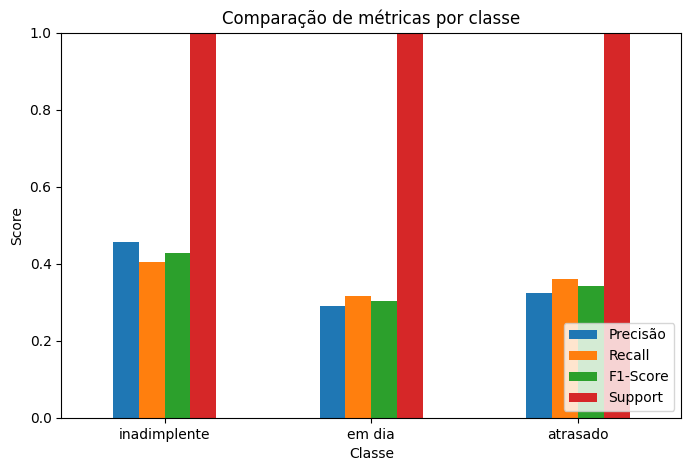

In [32]:
metrics_df.set_index("Classe", inplace=True)
metrics_df.plot(kind="bar", figsize=(8,5))
plt.title("Comparação de métricas por classe")
plt.ylabel("Score")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()



&nbsp;&nbsp;&nbsp;&nbsp; O segundo é um heatmap da matriz de confusão, que indica os acertos e erros do modelo para cada classe, com o eixo x representando as classes previstas e o eixo y as classes reais, facilitando a identificação de quais classes o modelo confunde mais e onde ele acerta ou erra.

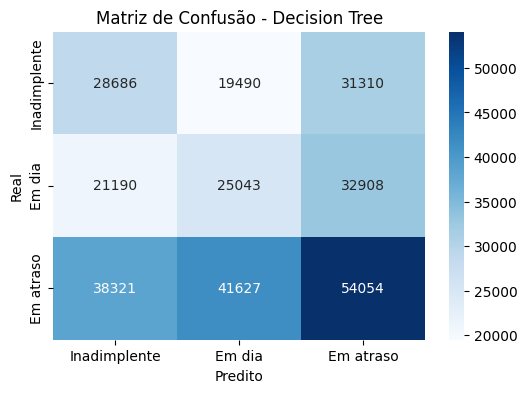

In [33]:

cm = confusion_matrix(y_test, y_pred)
labels = ["Inadimplente", "Em dia", "Em atraso"]

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predito")
plt.ylabel("Real")
plt.title("Matriz de Confusão - Decision Tree")
plt.show()



&nbsp;&nbsp;&nbsp;&nbsp; O modelo consegue prever tendências gerais de pagamento, mas tem um baixo desempenho entre as classes, acertando mais as majoritárias (“em dia”) e confundindo as minoritárias (“inadimplente” e “atrasado”). Após remover variáveis com data leakage como **vl_pagto**, **vl_ratio** e **dias_para_pagar**, a acurácia caiu, mas o modelo passou a generalizar melhor. Gráficos e matriz de confusão mostram claramente onde ele acerta e erra, indicando que há espaço para melhorar com features históricas ou modelos mais robustos.

&nbsp;&nbsp;&nbsp;&nbsp; Como próximos passos para este modelo preditivo, definimos melhorar a acurácia do modelo, para garantir uma maior taxa de acertos nas previsões e usar os dados de todas as tabelas disponibilizadas pela empresa parceira, assim acrescentando valor ao produto oferecido e entregando melhores resultados ao projeto. 

## 4.3 Modelo Preditivo B de Tendência de Pagamentos 

### 4.3.1 Features


Para treinar um modelo é necessário selecionar as **variáveis independentes (X)**, que são usadas como entrada para realizar a previsão, e a **variável dependente (y)**, que representa o valor a ser previsto.  

Neste modelo, foram reutilizadas as mesmas variáveis **X** do modelo anterior:  
- valor do boleto,  
- quantidade de acessos do pagador,  
- hash da inscrição do pagador,  
- juros,  
- mês do vencimento,  
- dia do vencimento,  
- tipo do pagador (CPF ou CNPJ).
- score médio de pagamento  

Além dessas, foi adicionada uma **nova feature derivada**:  
- **score_boleto_media** → representa o score médio de cada pagador, calculado com base no histórico de pagamentos. Essa métrica foi criada para capturar padrões individuais de risco de inadimplência.  

A variável **y** é o **status do pagamento** (em dia, em atraso ou inadimplente).  

### Categorias de Features
- **Variáveis Originais (normalizadas):** informações referentes ao boleto, ao pagador e ao histórico de pagamentos.  
- **Feature Derivada:** métrica construída a partir dos dados históricos para enriquecer o modelo.  


#### 4.3.2 Dividindo dados nos eixos x e y


- **X (features preditivas):** contém as variáveis explicativas normalizadas e criadas, incluindo **`score_boleto_media`**.  
- **y (variável alvo):** representa a classe de status do pagamento, podendo assumir três valores:  
  - Inadimplente  
  - Em dia  
  - Atrasado  


In [34]:
df_Treino = df_atual[df_atual['data_inclusao'] <= pd.Timestamp('2024-09-06')]
df_Test = df_atual[df_atual['data_inclusao'] >= pd.Timestamp('2024-09-07')]

X_train = df_Treino[['vl_boleto_norm', 
                 'qtd_acessos_pagador_norm', 
                 'pagador_inscricao_hash', 
                 'juros_norm',
                 'mes_vencimento_norm',
                 'dia_vencimento_norm',
                 'pagador_cnpjcpf_norm',
                 'score_boleto_media'
                 ]]
X_test = df_Test[['vl_boleto_norm', 
                 'qtd_acessos_pagador_norm', 
                 'pagador_inscricao_hash', 
                 'juros_norm',
                 'mes_vencimento_norm',
                 'dia_vencimento_norm',
                 'pagador_cnpjcpf_norm',
                 'score_boleto_media'
                 ]]
y_train = df_Treino['status_do_pagamento']
y_test = df_Test['status_do_pagamento']

### 4.3.3 Padronização e balanceamento refeita

#### Padronização
Os dados foram repadronizados para garantir que todas as **features** estivessem na mesma escala, evitando que variáveis com magnitudes maiores dominassem o treinamento do modelo.

#### Balanceamento
Como a distribuição das classes apresentava certo desbalanceamento, foram aplicadas técnicas de **balanceamento de classes**.  
Esse processo assegura que o modelo não fique enviesado em prever majoritariamente a classe mais frequente.  

Em muitos cenários de treinamento, as classes da variável **y** não estão igualmente representadas, gerando um **desbalanceamento**. Isso pode levar o modelo a ter uma "falsa precisão".  
Por exemplo: ao escolher uma letra aleatória do alfabeto, a chance de ser uma vogal é naturalmente menor que a de ser uma consoante. Se um modelo previsse sempre "consoante", ele pareceria estar correto na maioria dos casos, mas estaria enviesado.  

Para corrigir esse problema, foi utilizada a técnica **SMOTE (Synthetic Minority Over-sampling Technique)**, que gera amostras sintéticas das classes minoritárias, equilibrando os dados e reduzindo previsões "corretas" baseadas apenas na sorte.

In [35]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

sm = SMOTE(random_state=42)
X_train_res, y_train_res = sm.fit_resample(X_train_scaled, y_train)


O código realiza duas etapas fundamentais de preparação dos dados antes do treinamento do modelo. Primeiro, aplica o StandardScaler, que padroniza as variáveis numéricas, centralizando-as em torno da média e ajustando-as para desvio padrão igual a 1. Essa normalização garante que todas as features tenham a mesma escala, evitando que atributos com valores maiores dominem o aprendizado do modelo.

Em seguida, utiliza o SMOTE (Synthetic Minority Over-sampling Technique) para balancear o conjunto de treino, gerando amostras sintéticas das classes minoritárias. Essa técnica reduz o viés do modelo em relação à classe majoritária e melhora sua capacidade de generalização, especialmente em problemas de classificação desbalanceada. Assim, o código prepara os dados de forma adequada para garantir um treinamento mais justo e robusto do modelo.

### 4.3.4 Criando o Modelo B  

O **Modelo B** foi definido como o modelo preditivo geral do projeto.  
Para sua implementação, foi utilizado o algoritmo **Random Forest Classifier**, que se baseia em múltiplas árvores de decisão combinadas em *ensemble*.  

A escolha do Random Forest se deu pelo fato de o **Modelo A** ter utilizado apenas uma árvore de decisão. Ao aumentar o número de árvores, a robustez do modelo cresce, reduzindo a chance de **overfitting** e proporcionando previsões mais consistentes.  

### Configuração  
- **Algoritmo utilizado:** Random Forest  
  - O algoritmo combina diversas árvores de decisão para gerar a previsão final por meio de **voto majoritário**, resultando em maior estabilidade e precisão.  

### Hiperparâmetros  
Hiperparâmetros são configurações que controlam como o modelo aprende e podem influenciar diretamente o desempenho, evitando *overfitting*, balanceando respostas e controlando a complexidade do modelo.  
Os principais hiperparâmetros utilizados foram:  
- **n-estimators:** define quantas árvores de decisão o modelo vai construir no processo de treinamento
- **max_depth:** profundidade máxima da árvore, isto é, quantos níveis de divisão podem ser feitos.  
- **min_samples_split:** número mínimo de amostras necessárias para dividir um nó.  
- **min_samples_leaf:** número mínimo de amostras em um nó folha (nó terminal).  
- **criterion:** função usada para medir a qualidade da divisão (ex.: `gini` ou `entropy`).  
- **random_state:** fixado para garantir reprodutibilidade dos experimentos.  
- **bootstrap:** é uma técnica de amostragem com reposição — ou seja, o modelo treina cada árvore com um conjunto aleatório de amostras retiradas do dataset original, podendo repetir algumas e deixar outras de fora.
- **max_features:** define quantos atributos (features) o modelo pode usar a cada divisão (split) dentro de uma árvore da Random Forest.

### Vantagens do Random Forest  
- Redução de **overfitting** em comparação a uma árvore de decisão única.  
- Melhor **generalização** para dados não vistos.  
- **Robustez** na classificação de casos complexos, devido ao voto majoritário entre várias árvores.  


In [36]:

param_grid = {
    'n_estimators': [100, 300, 500],         # número de árvores
    'max_depth': [5, 10, 20, None],          # limite da profundidade
    'min_samples_split': [2, 5, 10, 20],     # tamanho mínimo para dividir nó
    'min_samples_leaf': [1, 2, 5, 10],       # tamanho mínimo da folha
    'max_features': ['sqrt', 'log2'],        # número de features por árvore
    'bootstrap': [True, False],              # uso de amostragem bootstrap
    'criterion': ['gini', 'entropy'],        # função de impureza
}

grid = RandomizedSearchCV(
    RandomForestClassifier(random_state=42, class_weight='balanced', n_jobs=-1),
    param_distributions=param_grid,
    n_iter=60,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid.fit(X_train_scaled, y_train)
best_tree = grid.best_estimator_
y_pred = best_tree.predict(X_test_scaled)

O código realiza o ajuste de hiperparâmetros de um modelo Random Forest Classifier utilizando o método RandomizedSearchCV, que testa combinações aleatórias de parâmetros para encontrar o melhor conjunto de configurações de forma mais eficiente do que o GridSearchCV completo.

O dicionário param_grid define os principais hiperparâmetros a serem otimizados, como o número de árvores (n_estimators), profundidade máxima (max_depth), número mínimo de amostras para divisão e folha (min_samples_split e min_samples_leaf), estratégia de seleção de variáveis (max_features), uso ou não de amostragem bootstrap e o critério de impureza (criterion).

O modelo é avaliado com validação cruzada de 5 folds (cv=5), e a métrica utilizada é a acurácia. Após o processo, o melhor modelo encontrado (best_tree) é treinado com os dados ajustados e realiza previsões (y_pred) no conjunto de teste. Esse procedimento garante uma busca otimizada por desempenho, resultando em um modelo mais preciso e equilibrado.

### 4.3.5 Métricas

Para mensurar o desempenho do modelo, foram utilizadas métricas amplamente aplicadas em problemas de classificação.  
Essas métricas permitem analisar tanto a performance global do modelo quanto o desempenho específico em cada classe.

- **Acurácia (Accuracy):** proporção de previsões corretas em relação ao total de observações.  
- **Precisão (Precision):** avalia, dentre as previsões positivas de uma classe, quantas foram realmente corretas.  
- **Recall (Sensibilidade):** mede a capacidade do modelo de identificar corretamente os exemplos positivos de uma classe.  
- **F1-Score:** média harmônica entre Precisão e Recall, balanceando as duas métricas.

Essas métricas foram calculadas considerando todas as classes com o parâmetro `average="weighted"`, o que pondera os resultados pelo número de ocorrências de cada classe.

#### 4.3.5.1 Relatório por Classe

Além das métricas gerais, foi gerado um **classification report** e uma tabela detalhada para cada classe:  
- **Classes avaliadas:**  
  - Inadimplente  
  - Em dia  
  - Atrasado  

Para cada classe, são reportados:  
- **Precisão (Precision):** qualidade das previsões positivas da classe.  
- **Recall:** capacidade de recuperação da classe pelo modelo.  
- **F1-Score:** equilíbrio entre precisão e recall.  
- **Support:** número de exemplos reais da classe no conjunto de teste.

Esse detalhamento possibilita identificar em quais classes o modelo apresenta maior ou menor desempenho, auxiliando na análise crítica de sua robustez.


In [37]:
# --- 1) Métricas gerais
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average="weighted")
rec = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")

print("Métricas do melhor modelo Decision Tree (geral):")
print(f"Acurácia: {acc:.4f}")
print(f"Precisão: {prec:.4f}")
print(f"Recall: {rec:.4f}")
print(f"F1-Score: {f1:.4f}")


y_test = pd.Series(y_test).astype(str).str.strip()
y_pred = pd.Series(y_pred).astype(str).str.strip()


classes = ["inadimplente", "em dia", "atrasado"]
print(classification_report(y_test, y_pred, labels=classes, target_names=classes, zero_division=0))


precision, recall, f1, support = precision_recall_fscore_support(
    y_test, y_pred, labels=classes, zero_division=0
)

metrics_df = pd.DataFrame({
    "Classe": classes,
    "Precisão": precision,
    "Recall": recall,
    "F1-Score": f1,
    "Support": support
})

print(metrics_df)

Métricas do melhor modelo Decision Tree (geral):
Acurácia: 0.4621
Precisão: 0.4684
Recall: 0.4621
F1-Score: 0.4636
              precision    recall  f1-score   support

inadimplente       0.53      0.47      0.50    134002
      em dia       0.41      0.42      0.41     79141
    atrasado       0.42      0.49      0.45     79486

    accuracy                           0.46    292629
   macro avg       0.45      0.46      0.46    292629
weighted avg       0.47      0.46      0.46    292629

         Classe  Precisão    Recall  F1-Score  Support
0  inadimplente  0.533016  0.469500  0.499246   134002
1        em dia  0.407858  0.421324  0.414481    79141
2      atrasado  0.419804  0.490338  0.452338    79486


O código avalia o desempenho do modelo de classificação calculando as métricas gerais — acurácia, precisão, recall e F1-Score — para medir sua performance global. Em seguida, ele padroniza os rótulos e gera um relatório detalhado por classe (“inadimplente”, “em dia” e “atrasado”), mostrando como o modelo se comporta em cada categoria. Por fim, organiza essas métricas em um DataFrame para facilitar a análise e identificar possíveis desequilíbrios entre as classes.

### 4.3.6 Gráficos Modelo B

**Visualização (gráficos):**  
Modelos preditivos retornam grande volume de dados, por isso é essencial utilizar gráficos para facilitar a interpretação.  

Os gráficos utilizados neste modelo foram:  
- **Gráfico de colunas:** para visualizar as métricas de cada categoria de status de pagamento.  
- **Mapa de calor da matriz de confusão:** para mostrar de forma clara como cada dado foi previsto em relação ao seu status real.


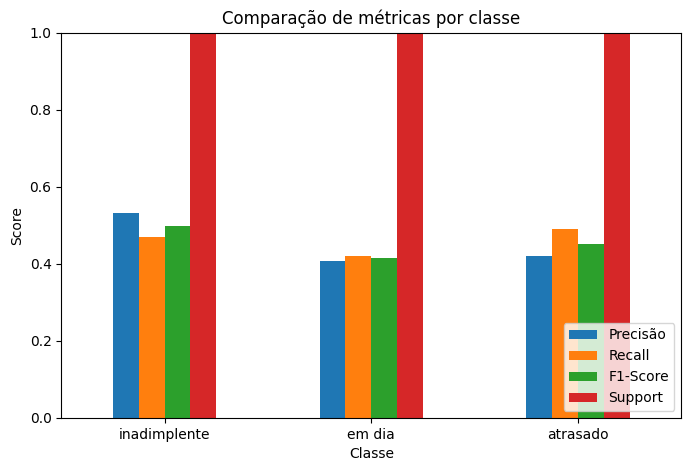

In [38]:
metrics_df.set_index("Classe", inplace=True)
metrics_df.plot(kind="bar", figsize=(8,5))
plt.title("Comparação de métricas por classe")
plt.ylabel("Score")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

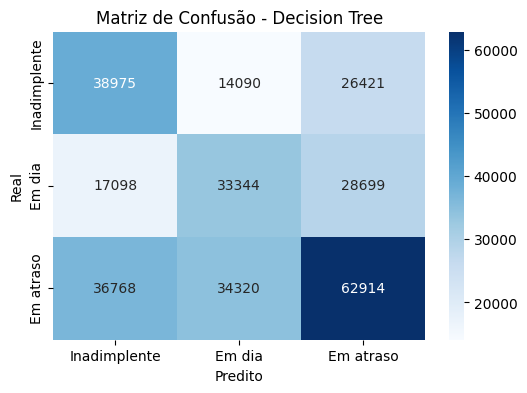

In [39]:

cm = confusion_matrix(y_test, y_pred)
labels = ["Inadimplente", "Em dia", "Em atraso"]

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predito")
plt.ylabel("Real")
plt.title("Matriz de Confusão - Decision Tree")
plt.show()


### 4.2.7 Explicação do Modelo Preditivo (Modelo B)

O **Modelo B** foi desenvolvido para prever o **status do pagamento** (inadimplente, em dia ou atrasado) utilizando como base o **Random Forest Classifier**, um algoritmo que combina várias árvores de decisão em um *ensemble*, aumentando a robustez e reduzindo o risco de *overfitting*.

#### Features Utilizadas
O modelo considera tanto variáveis originais quanto derivadas:

- **Variáveis originais (normalizadas):**  
  - valor do boleto  
  - quantidade de acessos do pagador  
  - hash da inscrição  
  - juros  
  - mês e dia de vencimento  
  - tipo do pagador (CPF ou CNPJ)
  - score médio de pagamento 

- **Feature derivada:**  
  - **score_boleto_media** → representa o score médio de cada pagador, capturando padrões históricos de risco de inadimplência

A variável alvo **y** é o **status do pagamento**.

#### Padronização e Balanceamento
- **Padronização:** todas as features foram colocadas na mesma escala para evitar que variáveis com magnitudes maiores dominassem o modelo.  
- **Balanceamento:** como as classes estavam desbalanceadas, foi utilizada a técnica **SMOTE** para gerar amostras sintéticas das classes minoritárias, garantindo que o modelo não previsse apenas a classe majoritária por sorte.

#### Configuração e Hiperparâmetros
- **max_depth:** profundidade máxima das árvores  
- **min_samples_split:** número mínimo de amostras para dividir um nó  
- **min_samples_leaf:** número mínimo de amostras em um nó folha  
- **criterion:** função de qualidade da divisão (ex.: `gini`)  
- **random_state:** fixado para reprodutibilidade

**Vantagens do Random Forest:** maior generalização, redução de overfitting e robustez na classificação de casos complexos.

#### Visualização e Interpretação
Para interpretar o modelo, foram utilizados gráficos:

- **Gráfico de colunas:** visualiza métricas por categoria de status  
- **Mapa de calor da matriz de confusão:** mostra previsões versus valores reais  

Além disso, o **SHAP (SHapley Additive exPlanations)** foi utilizado para explicar como cada feature contribuiu para as previsões do modelo:

- Permite analisar **previsões individuais**, mostrando se cada variável aumentou ou diminuiu a probabilidade de cada classe  
- Gera **visualizações globais**, mostrando quais features tiveram maior impacto no modelo  
- Complementa os gráficos tradicionais, trazendo transparência ao funcionamento do modelo e permitindo entender o **porquê das decisões** do Random Forest


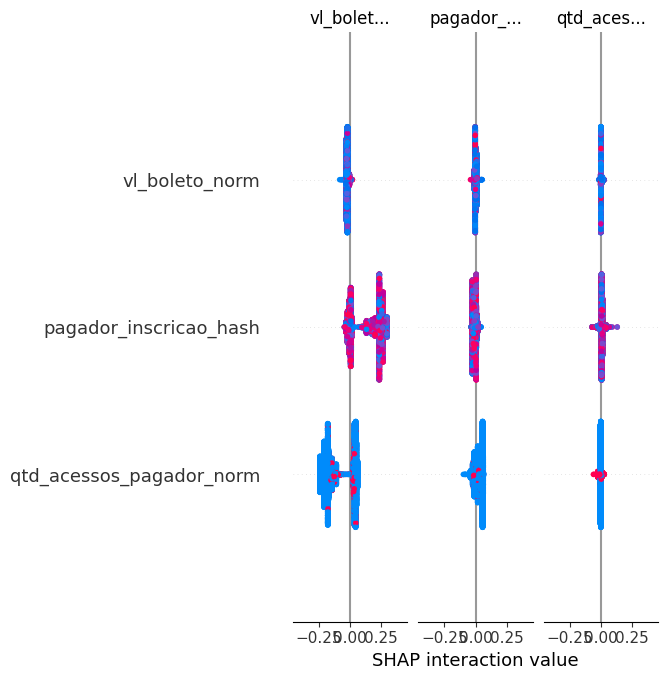

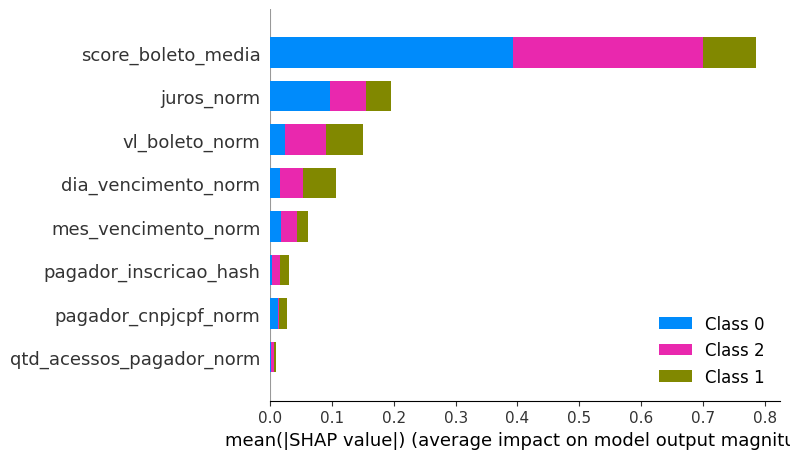

In [41]:
# Crie o explainer para o modelo RandomForest treinado acima
explainer = shap.TreeExplainer(best_tree)
# Amostra para o SHAP (pode ajustar o número se necessário)
X_sample = shap.sample(X_test, 10000, random_state=42)
# Calcula os valores SHAP
shap_values = explainer.shap_values(X_sample)
# Gráfico de resumo das importâncias das features
shap.summary_plot(shap_values, X_sample, feature_names=X_test.columns)
shap.summary_plot(shap_values, X_sample, feature_names=X_test.columns, plot_type="bar")

## 4.4 Modelo de Tendência de Pagamentos C

&nbsp;&nbsp;&nbsp;&nbsp; O LightGBM (Light Gradient Boosting Machine) é um algoritmo de aprendizado de máquina desenvolvido pela Microsoft, projetado especialmente para lidar com grandes volumes de dados de forma rápida, precisa e eficiente em termos de memória. Ele é uma versão otimizada da técnica Gradient Boosting, que constrói múltiplas árvores de decisão de maneira sequencial, em que cada nova árvore corrige os erros cometidos pelas anteriores.

&nbsp;&nbsp;&nbsp;&nbsp; Diferente de outras implementações, o LightGBM utiliza um método de crescimento de árvore chamado Leaf-Wise, que faz as divisões (splits) nas folhas que mais reduzem o erro, resultando em modelos mais precisos e com melhor desempenho computacional. Além disso, ele oferece suporte nativo a treinamento paralelo, GPU e tratamento eficiente de valores ausentes, o que o torna especialmente adequado para cenários de grande escala.


<br>
<div align="center">
<sub align="center">Figura 1 - Explicação do LightGBM</sub>
</div>
<br>
<div align="center">
<img src="../assets/lightGBM.jpg" alt="Histograma Valor do Boleto" border="0" width=50% height=50%>
</div>
<br>
<div align="center">
<sup>Fonte: Produzido pelo grupo The Seven, 2025.</sup>
</div>

&nbsp;&nbsp;&nbsp;&nbsp; No contexto deste projeto, o LightGBM é empregado para identificar a tendência de pagamento dos usuários, analisando padrões complexos nos dados financeiros e comportamentais. Essa abordagem garante previsões mais assertivas e escaláveis, mesmo quando aplicadas a bases de dados extensas e heterogêneas, permitindo uma tomada de decisão mais rápida e fundamentada.

### 4.4.1 Features


&nbsp;&nbsp;&nbsp;&nbsp;  Nesse caso, definimos quais variáveis vão compor o conjunto de entrada (X) e qual será a variável de saída (y). Em X, estão todas anteriormente selecionadas pelo modelo B, dessa forma, já utiliza da nova feature (score_boleto_media) para identificar a tendência de pagamento do usuário. Já em y, coloquei o status do pagamento, que é o resultado que queremos que o modelo aprenda a prever. Dessa forma, o problema está lidando com uma tarefa de classificação supervisionada, em que o modelo usará os dados dos boletos e dos pagadores para estimar se um pagamento será realizado ou não.

### 4.4.2 Dividindo dados entre treino e teste

&nbsp;&nbsp;&nbsp;&nbsp; Nessa parte do código, os dados são dividos entre teste e treino, sendo 20% reservado para teste e o restante dos 80% totalmente guardado para o treinamento do modelo. O X_train se refere ao X de treino, X_test se refere ao X de treino, o Y_train se refere ao y de treino e o y_test se refere ao Y de teste.

In [31]:
df_Treino = df_atual[df_atual['data_inclusao'] <= pd.Timestamp('2024-09-06')]
df_Test = df_atual[df_atual['data_inclusao'] >= pd.Timestamp('2024-09-07')]

X_train = df_Treino[['vl_boleto_norm', 
                 'qtd_acessos_pagador_norm', 
                 'pagador_inscricao_hash', 
                 'juros_norm',
                 'mes_vencimento_norm',
                 'dia_vencimento_norm',
                 'pagador_cnpjcpf_norm',
                 'score_boleto_media'
                 ]]
X_test = df_Test[['vl_boleto_norm', 
                 'qtd_acessos_pagador_norm', 
                 'pagador_inscricao_hash', 
                 'juros_norm',
                 'mes_vencimento_norm',
                 'dia_vencimento_norm',
                 'pagador_cnpjcpf_norm',
                 'score_boleto_media'
                 ]]
y_train = df_Treino['status_do_pagamento']
y_test = df_Test['status_do_pagamento']

Esse trecho de código divide o conjunto de dados em treino e teste com base na data de inclusão: registros até 06/09/2024 vão para o treino, e os a partir de 07/09/2024 vão para o teste. Em seguida, seleciona um conjunto de variáveis normalizadas (features) para compor X_train e X_test, como valor do boleto, acessos do pagador e dados de vencimento. Por fim, define y_train e y_test como a variável alvo status_do_pagamento, que o modelo deverá prever.

### 4.4.3 Padronização e balanceamento refeita

&nbsp;&nbsp;&nbsp;&nbsp; O trecho aplica uma padronização nos dados de treino e teste, transformando as variáveis preditoras para que tenham média zero e desvio padrão igual a um. Em seguida, utiliza a técnica SMOTE para realizar o balanceamento da base de treino, gerando novas amostras sintéticas da classe minoritária e equilibrando a distribuição entre as classes antes do treinamento do modelo.

In [ ]:

sm = SMOTE(random_state=42)
X_train_res, y_train_res = sm.fit_resample(X_train, y_train)

### 4.4.4 Criando o modelo

&nbsp;&nbsp;&nbsp;&nbsp; Como dito anteriormente, nesse modelo foi utilizado o LightGBM para identificar a tendência de pagamento do usuário. Para alcançar esse resultado, se fez necessário escolher os melhores hiper parâmetros possíveis para o nosso problema utilizando LightGradientBoosting. Os hiper parâmetros utilizados foram:

- **device="gpu"**: usa a GPU para acelerar o treinamento.
- **objective="multiclass"**: define que o problema tem múltiplas classes (use "binary" para 2 classes).
- **boosting_type="gbdt**: usa o método clássico de Gradient Boosting Decision Tree.
- **metric="multi_logloss**: mede o erro do modelo com base na entropia cruzada multiclasse.
- **class_weight="balanced**: ajusta automaticamente os pesos das classes para lidar com desbalanceamento.
- **n_jobs=-1**: utiliza todos os núcleos do processador para acelerar o treino.
- **random_state=42**: garante que os resultados sejam reprodutíveis.
- **num_leaves**: controla o número de folhas por árvore (mais folhas = mais complexidade e risco de overfitting).
- **max_depth**: define a profundidade máxima da árvore (-1 = ilimitado, valores menores controlam o overfitting).
- **learning_rate**: define o quanto cada nova árvore corrige os erros das anteriores (menor valor = aprendizado mais estável).
- **n_estimators**: número total de árvores no ensemble (mais árvores = mais precisão, mas treino mais lento).
- **min_child_samples**: número mínimo de amostras que cada folha precisa ter (valores maiores = modelo mais generalista).
- **subsample**: porcentagem de amostras usadas em cada árvore (bagging, evita overfitting).
- **colsample_bytree**: porcentagem de colunas (features) usadas em cada árvore (diversifica as árvores).
- **reg_alpha**: regularização L1 (Lasso), que pode eliminar variáveis irrelevantes.
- **reg_lambda**: regularização L2 (Ridge), que reduz pesos muito grandes e ajuda na generalização.
- **param_distributions**: dicionário com os intervalos dos hiperparâmetros a serem testados.
- **n_iter=50**: número de combinações de parâmetros aleatórias testadas (quanto mais, mais preciso).
- **scoring="accuracy"**: métrica de avaliação usada para escolher o melhor modelo (pode trocar por f1_macro).
- **cv=3**: número de divisões na validação cruzada (3 folds).
- **verbose=2**: exibe o progresso da busca no terminal.
- **random_state=42**: garante reprodutibilidade da busca.

&nbsp;&nbsp;&nbsp;&nbsp;     Nesse modelo, foi utilizado o LightGBM para prever a tendência de pagamento dos usuários, ajustando cuidadosamente os hiperparâmetros para maximizar o desempenho. O modelo foi configurado para classificação multiclasse, com balanceamento automático das classes, uso de GPU para acelerar o treinamento e validação cruzada para avaliar a performance. Os principais parâmetros ajustados controlam desde a complexidade das árvores (como num_leaves, max_depth e min_child_samples) até aspectos de regularização (reg_alpha, reg_lambda) e subamostragem (subsample, colsample_bytree), garantindo um bom equilíbrio entre precisão e generalização.

 

In [ ]:
model = lgb.LGBMClassifier(
    device="gpu",               # acelera usando GPU
    objective="multiclass",
    boosting_type="gbdt",
    metric="multi_logloss",
    class_weight="balanced",
    n_jobs=-1,
    random_state=42
)

# Espaço de busca reduzido e mais estratégico
param_dist = {
    "num_leaves": [31, 63, 127, 255],        # valores representativos
    "max_depth": [10, 15, 20],               # remove -1 (pode gerar árvores muito grandes)
    "learning_rate": [0.01, 0.05, 0.1],      # principais taxas
    "n_estimators": [200, 500, 1000],        # evita buscas muito longas
    "min_child_samples": [20, 50, 100],      # controle de overfitting
    "subsample": [0.7, 0.85, 1.0],
    "colsample_bytree": [0.7, 0.85, 1.0],
    "reg_alpha": [0.0, 0.1, 1.0],
    "reg_lambda": [0.0, 0.1, 1.0],
}

# Randomized Search mais leve
random_search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_dist,
    n_iter=15,            # ↓ de 50 para 15 (reduz tempo em ~70%)
    scoring="accuracy",
    cv=2,                 # ↓ de 3 para 2 folds
    verbose=1,
    random_state=42,
    n_jobs=-1
)

# Treinamento
random_search.fit(X_train_res, y_train_res)

# Melhor modelo
best_model = random_search.best_estimator_
print("✅ Melhores parâmetros encontrados:")
print(random_search.best_params_)

# Avaliação
y_pred = best_model.predict(X_test)

Fitting 2 folds for each of 15 candidates, totalling 30 fits


    Em vez do GridSearch, foi adotado o RandomizedSearchCV, já que o grande volume de dados tornava inviável testar todas as combinações possíveis. Assim, foram exploradas amostras aleatórias de hiperparâmetros dentro de intervalos definidos, reduzindo o tempo de execução e mantendo uma boa eficiência na busca por configurações ideais. Essa abordagem permitiu encontrar um modelo equilibrado e robusto, ajustado ao contexto e à profundidade dos dados analisados.

### 4.4.5 Métricas



&nbsp;&nbsp;&nbsp;&nbsp; Esse código faz a avaliação do desempenho do modelo treinado com o LightGBM. Primeiro, ele gera as previsões (y_pred) com base nos dados de teste e calcula as principais métricas globais: acurácia, precisão, recall e F1-Score. Em seguida, ele ajusta os valores das variáveis alvo e previstas para garantir consistência e organiza a avaliação por classe.

&nbsp;&nbsp;&nbsp;&nbsp; Foram consideradas três categorias de status de pagamento: “inadimplente”, “em dia” e “atrasado”. O relatório de classificação mostra o desempenho do modelo em cada classe, permitindo identificar diferenças de acerto entre os grupos. Por fim, os resultados são organizados em um DataFrame, detalhando para cada classe a precisão (proporção de previsões corretas dentro da classe), o recall (capacidade de identificar corretamente os casos da classe), o F1-Score (harmonia entre precisão e recall) e o suporte (quantidade real de amostras da classe no conjunto de teste).


In [ ]:
y_pred = model.predict(X_test_scaled)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average="weighted")
rec = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")

print("Métricas do melhor modelo Decision Tree (geral):")
print(f"Acurácia: {acc:.4f}")
print(f"Precisão: {prec:.4f}")
print(f"Recall: {rec:.4f}")
print(f"F1-Score: {f1:.4f}")


y_test = pd.Series(y_test).astype(str).str.strip()
y_pred = pd.Series(y_pred).astype(str).str.strip()


classes = ["inadimplente", "em dia", "atrasado"]
print(classification_report(y_test, y_pred, labels=classes, target_names=classes, zero_division=0))


precision, recall, f1, support = precision_recall_fscore_support(
    y_test, y_pred, labels=classes, zero_division=0
)

metrics_df = pd.DataFrame({
    "Classe": classes,
    "Precisão": precision,
    "Recall": recall,
    "F1-Score": f1,
    "Support": support
})

print(metrics_df)

&nbsp;&nbsp;&nbsp;&nbsp; Os resultados obtidos mostram que o modelo tem uma acurácia geral de aproximadamente 78,8%, com melhor desempenho nas classes “inadimplente” e “atrasado”, que apresentam F1-Scores acima de 0,80. Já a classe “em dia” apresentou desempenho inferior, com F1-Score próximo de 0,64, indicando maior dificuldade do modelo em distinguir corretamente essa categoria.

### 4.4.6 Gráficos

In [ ]:

cm = confusion_matrix(y_test, y_pred)
labels = ["Inadimplente", "Em dia", "Em atraso"]

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predito")
plt.ylabel("Real")
plt.title("Matriz de Confusão - Decision Tree")
plt.show()

## 4.5 Comparação dos Modelos de Tendência de Pagamento


&nbsp;&nbsp;&nbsp;&nbsp; Com objetivo de resolver o problema proposto pela Finnet com maior precisão e chance de acerto possível, o grupo desenvolveu 3 modelos com o mesmo objetivo: Identificar a tendência de pagamento do usuário, se será em dia, com atraso ou inadimplência. Através da criação desses três modelos, se tornou possível alterar os algoritmos de classificação, features utilizadas e hiperparâmetros específicos para cada caso, assim entregando maior valor para a empresa parceira e garantindo que o modelo entregue possui qualidade técnica e eficácia na resolução do problema.

&nbsp;&nbsp;&nbsp;&nbsp; Cada modelo, utilizou de um diferente algoritmo de classificação, sendo eles:
- Decision Tree Classifier para o modelo A.
- Random Forest Classifier para o modelo B.
- Light Gradient Boost Machine para o modelo C.

&nbsp;&nbsp;&nbsp;&nbsp;A diferença entre o método de classificação dos modelos é: O Decision Tree cria uma árvore de decisão para identificar a tendência de pagamentos do usuário, O Random Forest utiliza da criação de múltiplas árvores de decisão aleatórias e faz uma média de acurácia entre as árvores, e o Light Gradient Boosting também cria várias árvores de decisão, mas utiliza das árvores anteriores para aprender e aprimorar a árvore que surgirá posteriormente. 

&nbsp;&nbsp;&nbsp;&nbsp;Cada um desses modelos, possui características únicas, que se tornam pontos positivos para a escolha do modelo final, elas são:


**Decision Tree Classifier:**
- Rápido para treinar.
- Funciona bem sem normalização dos dados.
- Não lida tão bem com uma grande quantidade de dados.
- Utilizado para modelos mais "simples".

**Random Forest Classifier:**

- Reduz overfitting das árvores.
- Bom desempenho sem muito tuning.
- Pode ser mais pesado para dados enormes

**LGBM:**

- Pode-se usar GPU para processamento (Ou seja, mais rápido).
- Ótimo para problemas desbalanceados (class_weight).
- Lida melhor com uma grande quantidade de dados.

&nbsp;&nbsp;&nbsp;&nbsp; Após observar as características de cada algoritmo, a escolha parece clara: para o tamanho do dataset e o desbalanceamento das classes, o Modelo C (LightGBM) apresenta-se como a opção mais viável. Contudo, a definição do modelo preditivo não deve se basear apenas em aspectos teóricos. É necessário avaliar se os resultados práticos justificam essa escolha.

&nbsp;&nbsp;&nbsp;&nbsp; Para isso, na seção anterior, realizamos o treinamento e teste de cada um dos modelos candidatos, comparando-os pelas métricas de Acurácia, Precisão, Revocação (Recall) e F1-Score. E os resultados obtidos através deles foram:

|  Modelo  | Acurácia | Precisão |  Recall  | F1-Score |
|----------|----------|----------|----------|----------|
|     A    |    63%   |    65%   |    64%   |    64%   |
|     B    |    63%   |    67%   |    63%   |    63%   |
|     C    |    75%   |    76%   |    75%   |    76%   |

&nbsp;&nbsp;&nbsp;&nbsp; Através dos resultados obtidos, é possível identicar que na média das métricas para cada uma das classes (em dia, atraso e inadimplente), o modelo C foi o que apresentou maior acurácia, precisão, revocação e F1-Score entre os modelos analisados. Além disso, os modelos B e C utilizam de uma nova feature, chamada score_boleto_media, que utiliza do histórico de pagamentos anteriores de cada devedor para identificar sua tendência de pagamento futura, o que pode influenciar diretamente nos resultados distintos entre os modelos. A equipe também comparou o tempo que cada um dos modelos precisa para ser executado, o resultado foi:

|  Modelo  | Tempo necesário para execução | 
|----------|-------------------------------|
|     A    |             6min              |
|     B    |             7min              |
|     C    |            36min              |

&nbsp;&nbsp;&nbsp;&nbsp; A diferença de tempo observada entre os modelos está diretamente relacionada aos hiperparâmetros e à estratégia de busca utilizada em cada caso. Os Modelos A e B (Árvore de Decisão e Random Forest) foram ajustados por meio do método GridSearchCV, que realiza uma busca exaustiva dentro dos limites estabelecidos para cada hiperparâmetro. Embora esse procedimento garanta uma seleção sistemática, ele aumenta consideravelmente o tempo de execução, pois o modelo é treinado diversas vezes com diferentes combinações de parâmetros.

&nbsp;&nbsp;&nbsp;&nbsp; Por outro lado, o Modelo C (LightGBM) não utilizou o GridSearch, mas sim do RandomizedSearch, buscando uma busca mais rápida devido a grande quantidade de dados. Apesar de teoricamente o Modelo C ser mais rápido na teoria, na prática, ele levou um tempo elevado para execução. Isso porque ele utiliza de alguns com valores elevados, como o n_estimators = 2000, que implica na construção de até duas mil árvores de decisão. À primeira vista, esse número poderia sugerir um custo computacional muito maior do que os modelos A e B. No entanto, o LightGBM foi projetado com técnicas de otimização que reduzem drasticamente o tempo de treinamento. Essas características permitem que o LightGBM treine milhares de árvores em menos tempo do que seria necessário para treinar algumas centenas em um Random Forest tradicional. Portanto, apesar do maior número de estimadores, o Modelo C alcançou melhor desempenho sem comprometer a eficiência, demonstrando sua adequação para cenários com grande volume de dados e classes desbalanceadas.

&nbsp;&nbsp;&nbsp;&nbsp; Além dos pontos já mencionados, é importante destacar que o Modelo B faz uso do hiperparâmetro **n_jobs=-1**, que instrui o algoritmo a utilizar todos os núcleos disponíveis do processador. Nesse caso, a paralelização ocorre em dois níveis: tanto na execução interna do próprio algoritmo quanto no processo de GridSearchCV, o que amplia o ganho de eficiência. Já o Modelo A aplica o **n_jobs=-1** apenas na etapa de treinamento do algoritmo em si, sem o mesmo benefício adicional no processo de busca de hiperparâmetros.

&nbsp;&nbsp;&nbsp;&nbsp;Essa diferença explica por que ambos os modelos apresentaram tempos de execução semelhantes, mesmo possuindo níveis de complexidade distintos, afinal, a Random Forest (Modelo B) é naturalmente mais custosa que uma única Árvore de Decisão (Modelo A), mas o aproveitamento mais amplo da paralelização reduz esse impacto.

### 4.5.1 Comparação por classes

&nbsp;&nbsp;&nbsp;&nbsp; Na seção anterior, verificamos que o modelo C apresentou médias superiores em todas as métricas avaliadas. Entretanto, isso não significa necessariamente que ele tenha o melhor desempenho em métricas específicas. Para identificar o modelo mais adequado em cada situação, realizamos o cálculo das métricas individualmente para cada classe. Os resultados estão apresentados a seguir:

| Modelo | Precisão Inadimplente | Precisão em dia | Precisão atrasado | Recall Inadimplente | Recall em dia | Recall atrasado | F1 Score Inadimplente | F1 Score em dia | F1 Score atrasado |
|--------|------------------------|-----------------|-------------------|---------------------|---------------|-----------------|-----------------------|-----------------|-------------------|
| A      | 70%                   | 38%             | 72%               | 66%                 | 47%           | 68%             | 68%                   | 42%             | 70%               |
| B      | 75%                   | 42%             | 69%               | 49%                 | 64%           | 76%             | 59%                   | 50%             | 73%               |
| C      | <span style="color:green; font-weight:bold">78%</span> | <span style="color:green; font-weight:bold">57%</span> | <span style="color:green; font-weight:bold">82%</span> | <span style="color:green; font-weight:bold">75%</span> | <span style="color:green; font-weight:bold">65%</span> | <span style="color:green; font-weight:bold">80%</span> | <span style="color:green; font-weight:bold">77%</span> | <span style="color:green; font-weight:bold">61%</span> | <span style="color:green; font-weight:bold">81%</span> |



&nbsp;&nbsp;&nbsp;&nbsp; A tabela mostra que o Modelo C apresenta o melhor desempenho geral, superando os demais em todas as métricas e em todas as classes. Isso indica que ele é mais consistente e equilibrado, entregando os maiores valores de precisão, recall e F1 Score independentemente da categoria avaliada. O Modelo A, por outro lado, tem desempenho mais fraco, especialmente na classe “em dia”, onde seus valores são significativamente inferiores aos dos demais, sugerindo dificuldade em classificar corretamente essa categoria. Já o Modelo B ocupa uma posição intermediária: em alguns casos consegue superar o Modelo A, mas ainda permanece abaixo do Modelo C em todos os aspectos. 

## 4.5.2 Conclusões

&nbsp;&nbsp;&nbsp;&nbsp; Após a execução de todos os modelos, definimos como algoritmo definitivo para o modelo de tendência de pagamento o C (LightGBM), uma vez que apresentou desempenho superior em todas as métricas avaliadas, garantindo maior equilíbrio entre precisão, recall e F1 Score nas diferentes classes. Dessa forma, ele se mostra a escolha mais adequada para aplicação prática do sistema.

#### 4.5.2.2 Dificuldades

&nbsp;&nbsp;&nbsp;&nbsp; Apesar dos resultados, encontramos algumas dificuldades ao decorrer da sprint, sendo elas:

- Dificuldade na busca por hiperparâmetros pela falta de processamento dos nossos equipamentos.
- Complicações na instalação do Pycaret.
- Problemas em lidar com uma grande quantidade de dados.

#### 4.5.2.2 Planos Futuros

Definimos como planos futuros para o projeto: 

- Utilizar o GridSearch no modelo C (Não foi possível durante essa essa Sprint por conta da falta de processamento dos nossos equipamentos)
- Melhorar a acurácia do modelo, principalmente para boletos **em dia**.
- Testar o modelo escolhido.
- Dedicar esforços a criação de um Dashboard funcional.

